# GSE267053

| Cell/Tissue | Organism | Source | Strand | Library | Genotype | Group | Treatment |
| - | - | - | - | - | - | - | - |
| mESC | Mus musculus | Embryonic stem cells | R1 | RNA-seq (PolyA) | Dnmt1-tet/tet | Control (CTL) | Untreated |
| mESC | Mus musculus | Embryonic stem cells | R1 | RNA-seq (PolyA) | Dnmt1-tet/tet | Inactive (INV) | Doxycycline (2 μg/mL) for 6 days |
| mESC | Mus musculus | Embryonic stem cells | R1 | RNA-seq (PolyA) | Dnmt1-tet/tet | Rescue (RES) | Doxycycline (2 μg/mL) for 6 days, then recovery for 21 days |

- Elizabeth Elder, Anthony Lemieux, et al. Rescuing DNMT1 fails to fully reverse the molecular and functional repercussions of its loss in mouse embryonic stem cells, Nucleic Acids Research, Volume 53, Issue 4, 28 February 2025, gkaf130, https://doi.org/10.1093/nar/gkaf130

In [1]:
library(tidyverse)

suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))

suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.2
✔ ggplot2   3.5.2     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Loading Data

In [2]:
data_dir <- "~/data1/GSE267053_mESC_DNMT1/mRNAseq/output"

In [3]:
countMat <- file.path(data_dir, "05_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)
    # data.table::fread(check.names = FALSE)

colnames(countMat) <- colnames(countMat) |> 
    sub("^output/04_star/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    # sub("^output/04_hisat2/(.*?).bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(countMat)

[1] 55421    17

In [4]:
coldata <- colnames(countMat) |>
    (\(x) x[grepl("mESC", x, fixed = TRUE)])() |>
    tibble(Sample = _) |>
    separate(col = Sample, into = c("Cell", "Genotype", "Group", "Replicate"), 
             sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(Sample = sub("^[^_]+_[^_]+_", "", Sample),
           Group = factor(Group, levels = c("CTL", "INV", "RES")), 
           Replicate = factor(Replicate)) |> 
    column_to_rownames("Sample")

coldata

,Cell,Genotype,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
CTL_rep1,mESC,Dnmt1tet,CTL,rep1
CTL_rep2,mESC,Dnmt1tet,CTL,rep2
CTL_rep3,mESC,Dnmt1tet,CTL,rep3
INV_rep1,mESC,Dnmt1tet,INV,rep1
INV_rep2,mESC,Dnmt1tet,INV,rep2
INV_rep3,mESC,Dnmt1tet,INV,rep3
RES_rep1,mESC,Dnmt1tet,RES,rep1
RES_rep2,mESC,Dnmt1tet,RES,rep2
RES_rep3,mESC,Dnmt1tet,RES,rep3


In [5]:
geneAnno <- countMat |> 
    select(Geneid, symbol = gene_name, type = gene_type, 
           basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
countMat <- countMat |>
    column_to_rownames("Geneid") |>
    select(matches("mESC")) |>
    rename_with(~ sub("^[^_]+_[^_]+_", "", .x)) |>
    as.matrix()

In [7]:
dds <- DESeqDataSetFromMatrix(
    countData = countMat, 
    rowData = geneAnno, 
    colData = coldata, 
    design = ~ 0 + Group)
dds

class: DESeqDataSet 
dim: 55421 9 
metadata(1): version
assays(1): counts
rownames(55421): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000095019.1 ENSMUSG00000095041.7
rowData names(3): symbol type basepairs
colnames(9): CTL_rep1 CTL_rep2 ... RES_rep2 RES_rep3
colData names(4): Cell Genotype Group Replicate

In [8]:
dge <- DGEList(
    counts = countMat, 
    genes = geneAnno, 
    samples = coldata, 
    group = coldata$Group)

In [9]:
dim(dds)
keep <- rowSums(counts(dds) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= ceiling(0.2 * ncol(dds))
dds <- dds[keep, ]
dim(dds)

[1] 55421     9

[1] 17887     9

In [10]:
dim(dge$counts)
keep <- filterByExpr(dge, group = dge$samples$group)
dge <- dge[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dge <- normLibSizes(dge)
dim(dge$counts)

[1] 55421     9

[1] 17738     9

# 2. Normalization
1. Sequencing Depth: CPM, FPKM/RPKM, TPM, DESeq2, edgeR's TMM
2. Gene Length: FPKM/RPKM, TPM
3. RNA Composition, a small number of genes account for a large number of reads: DESeq2, edgeR's TMM

In [11]:
tpm <- counts(dds) |>
    sweep(1, rowData(dds)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [12]:
rld <- rlog(dds, blind = FALSE)

In [13]:
suppressPackageStartupMessages(library(vsn))

In [14]:
common_theme <- theme_classic() +
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16),
          axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16))

In [15]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme

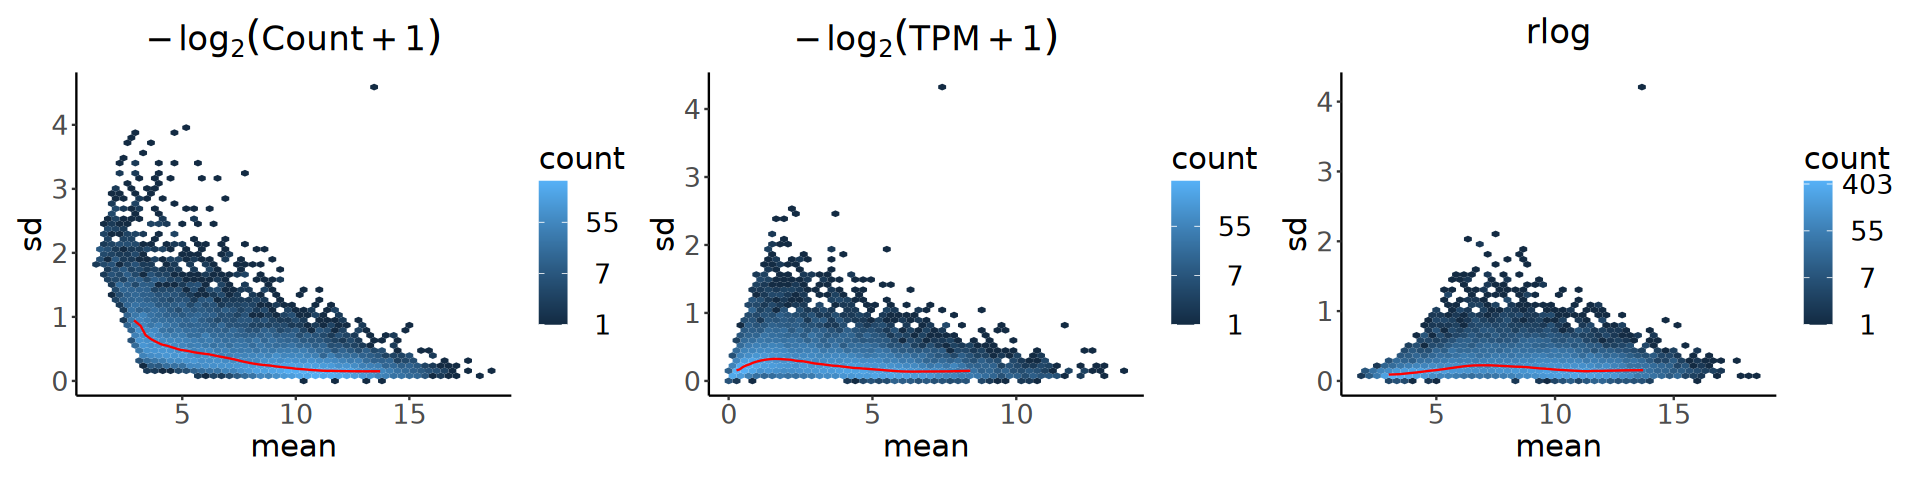

In [16]:
options(repr.plot.width = 16, repr.plot.height = 4)
p1 + p2 + p3

# 3. Exploration

In [17]:
normExpr <- log2(tpm + 1)

### 1). Overview

In [18]:
plot_df <- colData(dds) |> as.data.frame() |>
    rownames_to_column(var = "Sample") |>
    arrange(Group, Replicate) |> 
    mutate(librarySize = colSums(counts(dds))[Sample], 
           Sample = gsub("_", "\n", Sample),
           Sample = factor(Sample, levels = Sample))

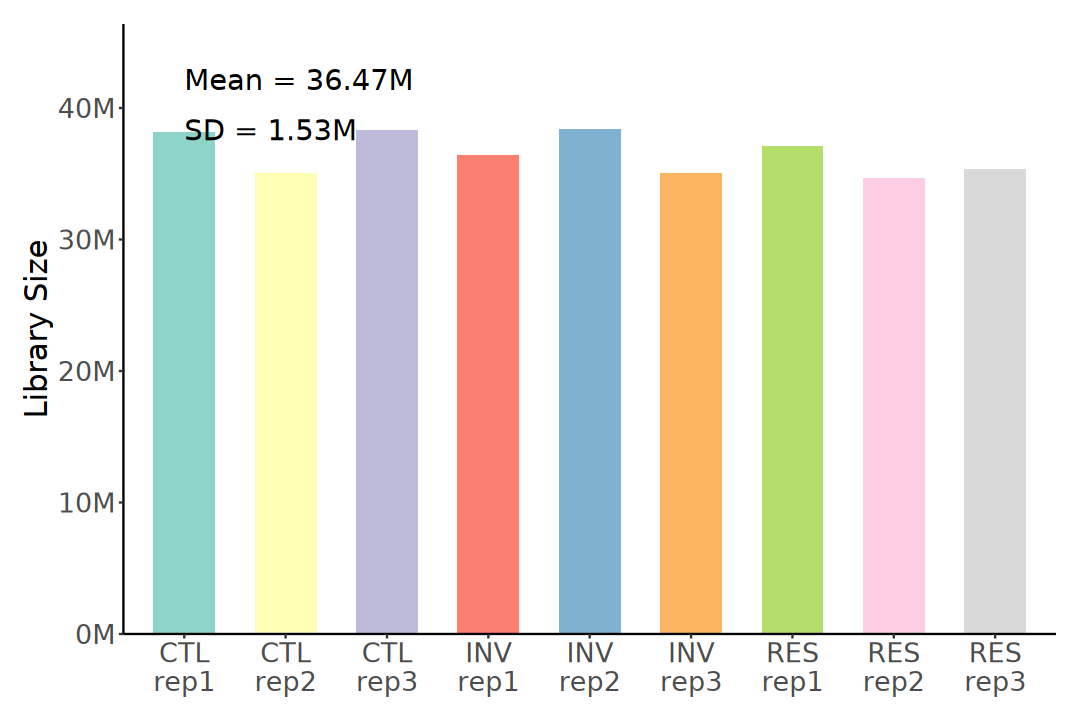

In [19]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(plot_df, aes(x = Sample, y = librarySize)) +
    geom_col(aes(fill = Sample), width = 0.6, show.legend = FALSE) +
    annotate(
        geom = "text", x = 1, y = max(plot_df$librarySize) * 1.1,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 1, y = max(plot_df$librarySize) * 1,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set3") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16), 
          plot.margin = unit(c(1, 1, 1, 1), "line"))

## 2). PCA

In [20]:
# CV can eliminate the bias that "high abundance tends to have large variance".
top_idx <- normExpr |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> 
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)

In [21]:
pca_res <- normExpr[top_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x[, 1:3], 
                colData(dds)[, c("Group", "Replicate")], 
                by = "row.names")

In [22]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), 
               size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    labs(title = bquote("PCA for" ~ -log[2](TPM+1)), 
         x = paste0("PC1: ", per_var[1], "% variance"),
         y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(color = guide_legend(override.aes = list(size = 5)), 
           shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16),
          axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16))

In [23]:
pca_res <- plotPCA(rld, intgroup = c("Group", "Replicate"), 
                   ntop = 2000, returnData = TRUE)
percentVar <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [24]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), 
               size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "PCA for rlog", 
         x = paste0("PC1: ", percentVar[1], "% variance"),
         y = paste0("PC2: ", percentVar[2], "% variance")) +
    guides(color = guide_legend(override.aes = list(size = 5)), 
           shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16),
          axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16))

In [25]:
# Generalized principal component analysis (GLM-PCA)
suppressPackageStartupMessages(library(glmpca))

In [26]:
gpca <- glmpca(counts(dds)[top_idx, ], L = 2)

Warning message in glmpca(counts(dds)[top_idx, ], L = 2):
“Reached maximum number of iterations (1000) without numerical convergence. Results may be unreliable.”


In [27]:
gpca_df <- gpca$factors |> 
    merge(colData(dds)[,c("Group", "Replicate")], by = "row.names")

In [28]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Replicate), 
               size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count",
         x = "PC1", y = "PC2") +
    guides(color = guide_legend(override.aes = list(size = 5)), 
           shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16),
          axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16))

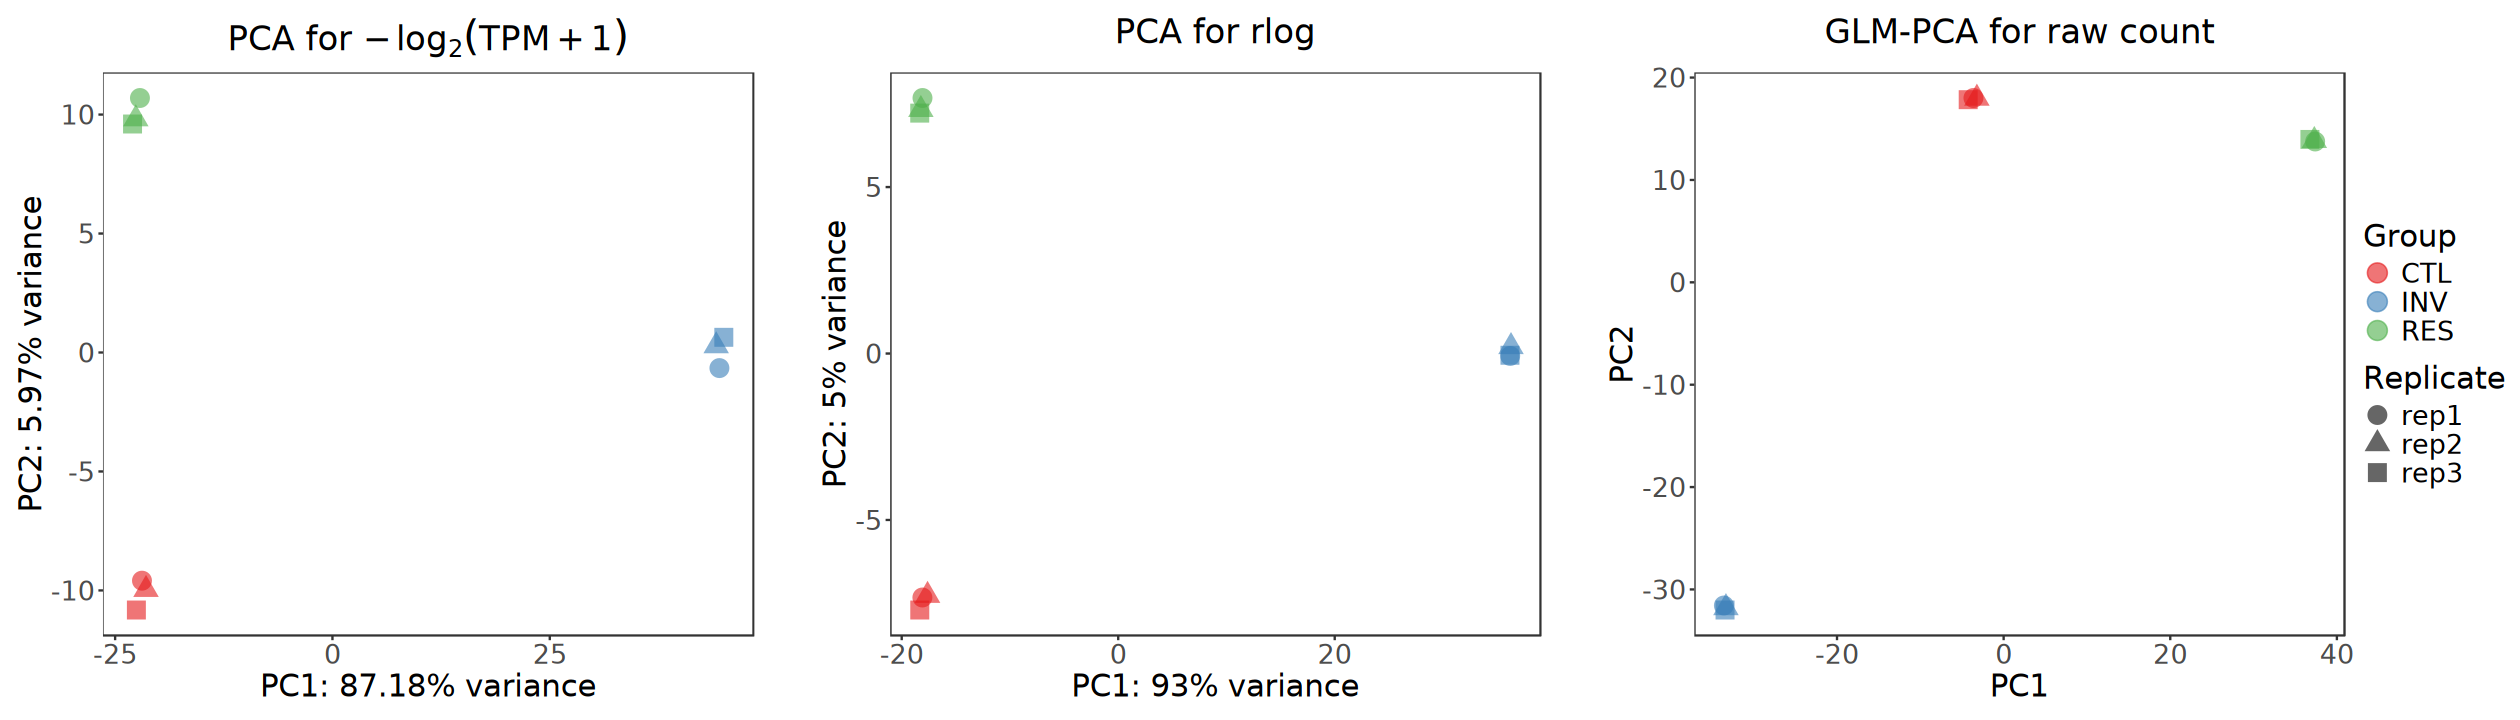

In [29]:
options(repr.plot.width = 21, repr.plot.height = 6)
p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS
Multidimensional scaling

In [30]:
dist_mat <- normExpr[top_idx, ] |> t() |> dist()

In [31]:
mds <- as.data.frame(colData(dds)) |>
    cbind(cmdscale(as.matrix(dist_mat)))

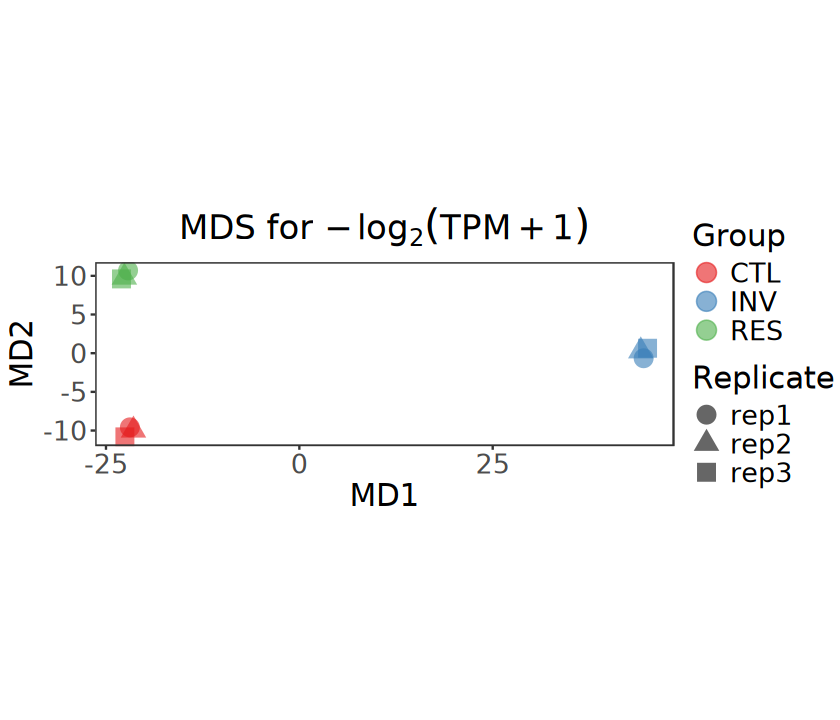

In [32]:
options(repr.plot.width = 7, repr.plot.height = 6)
ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Replicate), 
               size = 5, alpha = 0.6) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    ggtitle(bquote("MDS for" ~ -log[2](TPM+1))) + 
    labs(x = "MD1", y = "MD2") +
    guides(color = guide_legend(override.aes = list(size = 5)), 
           shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16),
          axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16))

## 4). Expression Heatmap

In [33]:
ac <- colData(dds) |>
    as.data.frame() |>
    dplyr::select(Replicate, Group)

In [34]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

anno_colors <- list(Group = group_colors,
                    Replicate = replicate_colors)

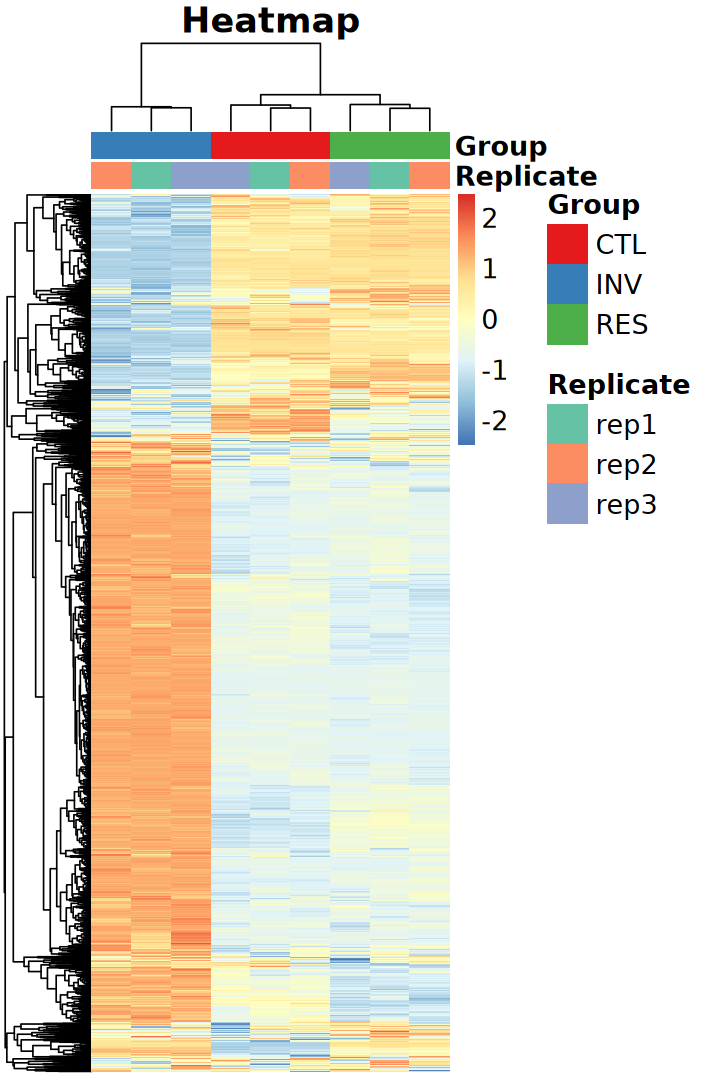

In [35]:
options(repr.plot.width = 6, repr.plot.height = 9)
pheatmap(normExpr[top_idx, ], scale = "row", 
         annotation_col = ac, 
         annotation_colors = anno_colors, 
         main = "Heatmap", fontsize = 16, 
         show_colnames = FALSE, show_rownames = FALSE)

## 5). Sample Distance

In [36]:
dist_mat <- normExpr[top_idx, ] |> t() |> dist()

In [37]:
colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

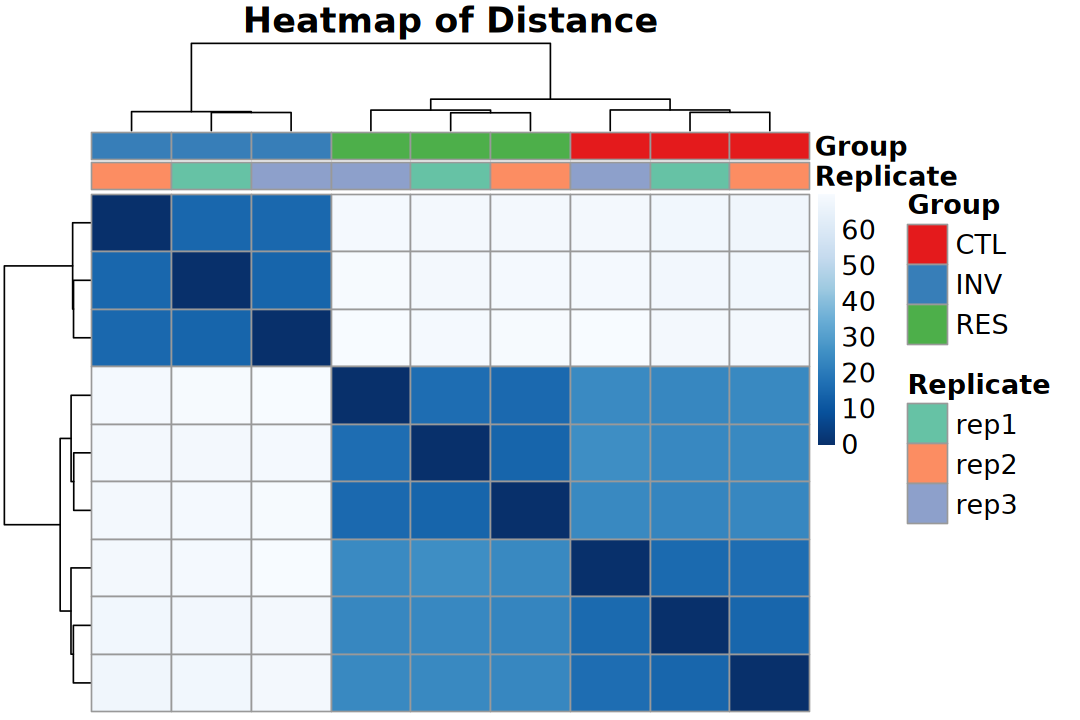

In [38]:
options(repr.plot.width = 9, repr.plot.height = 6)
pheatmap(as.matrix(dist_mat),
         clustering_distance_rows = dist_mat,
         clustering_distance_cols = dist_mat,
         annotation_col = ac, col = rev(colors), 
         annotation_colors = anno_colors,
         main = "Heatmap of Distance", fontsize = 16, 
         show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

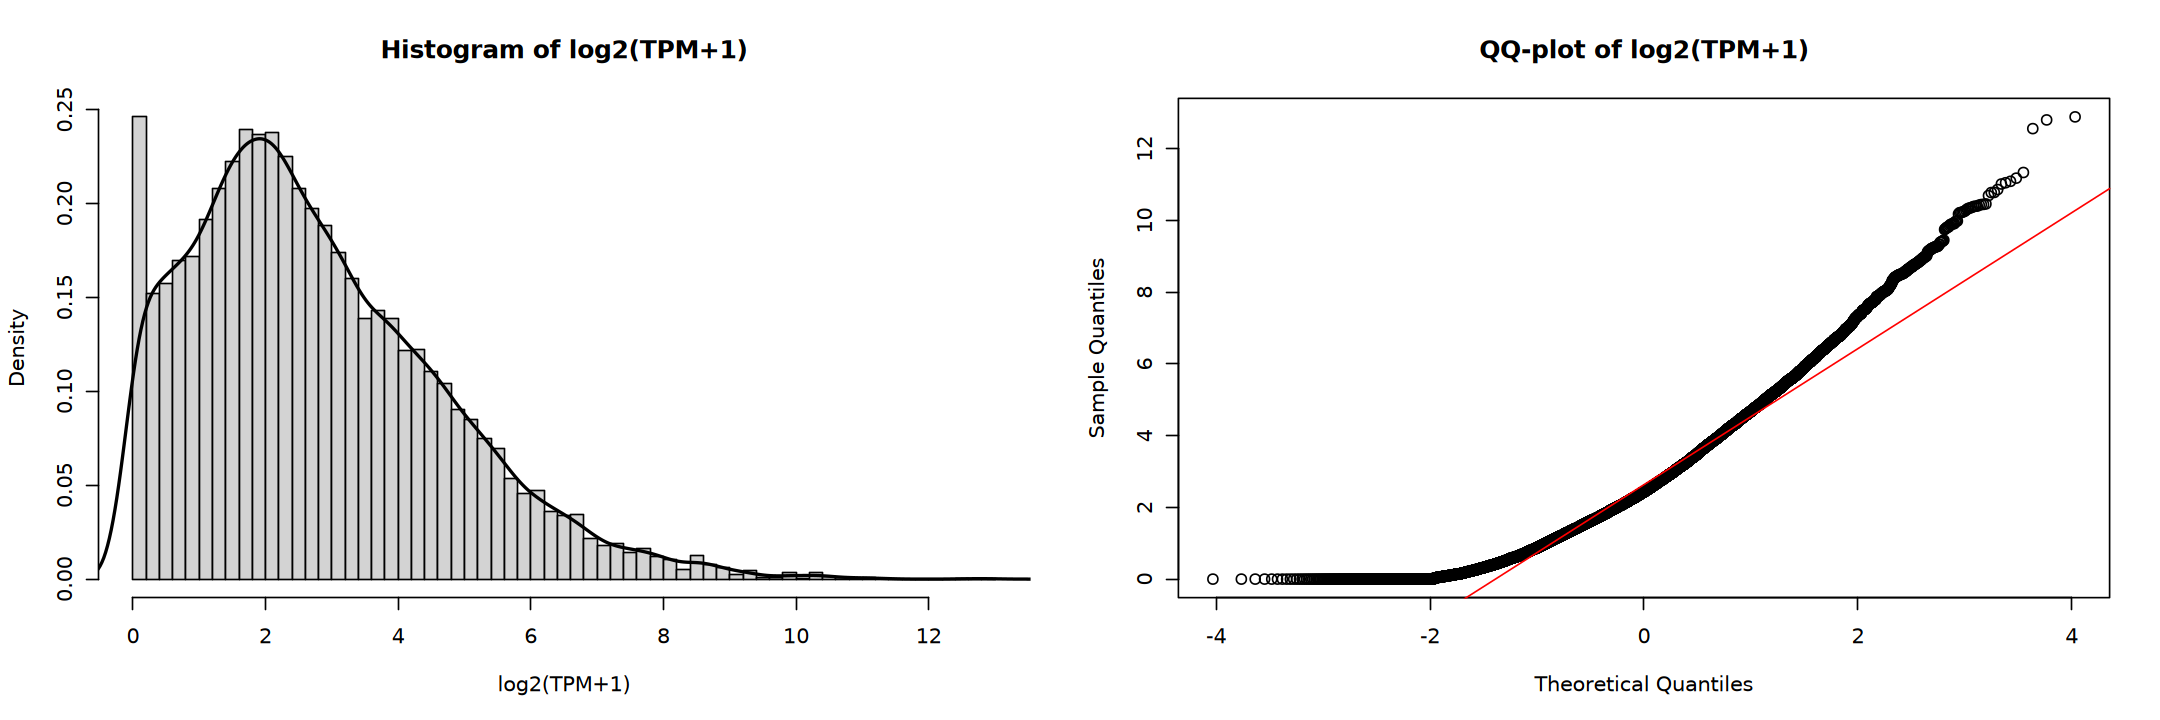

In [39]:
options(repr.plot.width = 18, repr.plot.height = 6)

par(mfrow = c(1, 2))
hist(normExpr[top_idx, ], breaks = 50, probability = TRUE, 
     main = "Histogram of log2(TPM+1)", 
     xlab = "log2(TPM+1)")
lines(density(normExpr[top_idx, ]), lwd = 2)

qqnorm(normExpr[top_idx, ], main = "QQ-plot of log2(TPM+1)")
qqline(normExpr[top_idx, ], col = "red")

par(mfrow = c(1, 1))

In [40]:
# cor_mat <- cor(normExpr[top_idx, ], method = "pearson")
cor_mat <- cor(normExpr[top_idx, ], method = "spearman")

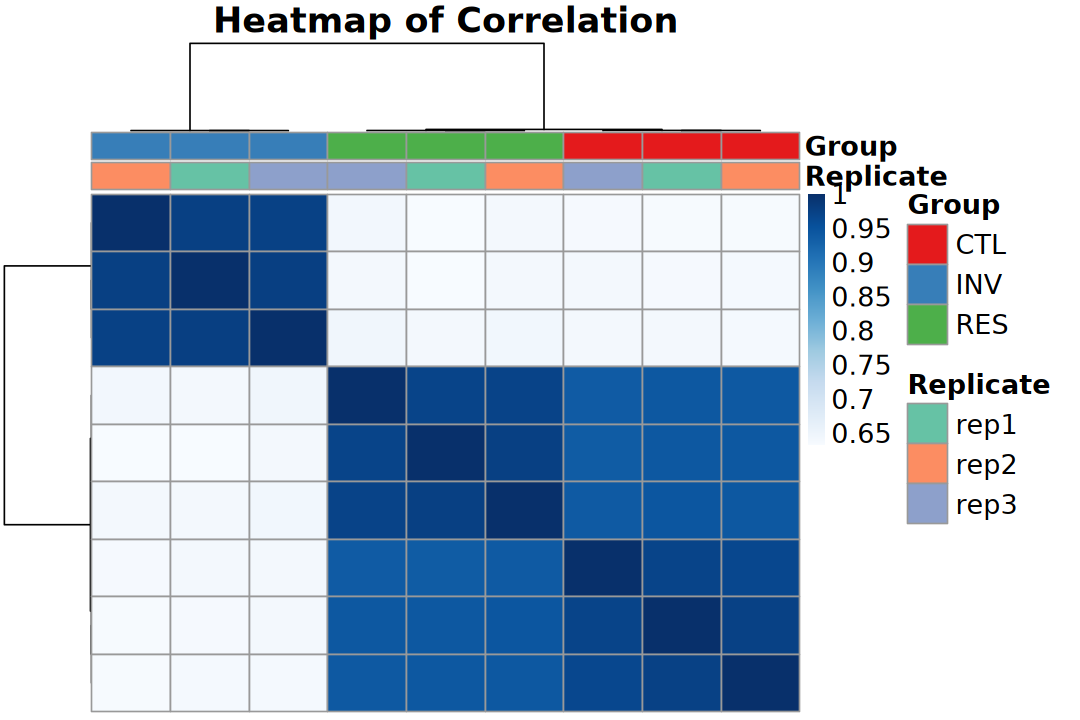

In [41]:
options(repr.plot.width = 9, repr.plot.height = 6)
pheatmap(as.matrix(cor_mat), 
         clustering_distance_rows = "correlation",
         clustering_distance_cols = "correlation",
         annotation_col = ac, col = colors, 
         annotation_colors = anno_colors,
         main = "Heatmap of Correlation", fontsize = 16, 
         show_colnames = FALSE, show_rownames = FALSE)

# 6. DEG

In [42]:
logFC_thred <- log2(2)
q_thred <- 0.05

## 1). DESeq2
median of ratios for normalization

In [43]:
design(dds)

~0 + Group

In [44]:
dds <- DESeq(dds)
resultsNames(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] "GroupCTL" "GroupINV" "GroupRES"

In [45]:
comparisons <- combn(levels(dds$Group), 2, simplify = FALSE)
comparisons
compar_levels <- map_chr(comparisons, ~ paste0(.x[2], "_vs_", .x[1]))
compar_levels

[[1]]
[1] "CTL" "INV"

[[2]]
[1] "CTL" "RES"

[[3]]
[1] "INV" "RES"

[1] "INV_vs_CTL" "RES_vs_CTL" "RES_vs_INV"

In [46]:
deg_deseq2_list <- map(comparisons, function(lv) {
    results(dds, contrast = c("Group", lv[2], lv[1])) |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            deg = case_when(
                padj < q_thred & logFC >  logFC_thred ~ "Up",
                padj < q_thred & logFC < -logFC_thred ~ "Down",
                TRUE ~ "NotSig"
            ) |> factor(levels = c("Up", "Down", "NotSig")), 
            compar = paste0(lv[2], "_vs_", lv[1])) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(compar_levels)

In [47]:
deg_df <- bind_rows(deg_deseq2_list) |>
    group_by(compar, deg) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                deg %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(compar = factor(compar, levels = compar_levels))

table(deg_df$deg, deg_df$compar)

        
         INV_vs_CTL RES_vs_CTL RES_vs_INV
  Up           1970         99       1214
  Down         1197        209       2006
  NotSig      14720      17579      14667

In [48]:
# deg_deseq2_list <- map(compar_levels, function(lv) {
#     lfcShrink(dds, coef = paste0("Group_", lv), type = "apeglm") |>
#         as.data.frame() |> 
#         rownames_to_column("gene_id") |>
#         dplyr::rename(logFC = log2FoldChange) |>
#         mutate(
#             deg = case_when(
#                 padj < q_thred & logFC >  logFC_thred ~ "Up",
#                 padj < q_thred & logFC < -logFC_thred ~ "Down",
#                 TRUE ~ "NotSig"
#             ) |> factor(levels = c("Up", "Down", "NotSig")), 
#             compar = paste0(lv[2], "_vs_", lv[1])) |>
#         left_join(
#             rowData(dds) |> as.data.frame() |> 
#                 dplyr::select(symbol, type, basepairs) |>
#                 rownames_to_column("gene_id"), 
#             by = "gene_id")
# }) |> set_names(compar_levels)

## 2). edgeR
Quasi-likelihood pipeline (edgeR v3)

In [49]:
# design <- model.matrix(~ group, data = dge$samples) # include intercept
design <- model.matrix(~ 0 + group, data = dge$samples) # no include intercept
colnames(design) <- levels(dge$samples$group)
design

,CTL,INV,RES
CTL_rep1,1,0,0
CTL_rep2,1,0,0
CTL_rep3,1,0,0
INV_rep1,0,1,0
INV_rep2,0,1,0
INV_rep3,0,1,0
RES_rep1,0,0,1
RES_rep2,0,0,1
RES_rep3,0,0,1


In [50]:
comparisons <- combn(levels(dds$Group), 2, simplify = FALSE)
comparisons
compar_levels <- map_chr(comparisons, ~ paste0(.x[2], "_vs_", .x[1]))
compar_levels

[[1]]
[1] "CTL" "INV"

[[2]]
[1] "CTL" "RES"

[[3]]
[1] "INV" "RES"

[1] "INV_vs_CTL" "RES_vs_CTL" "RES_vs_INV"

In [51]:
contrast_mat <- comparisons |> 
    map(function(lv) {paste0(lv[2], "-", lv[1])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_mat

,INV-CTL,RES-CTL,RES-INV
CTL,-1,-1,0
INV,1,0,-1
RES,0,1,1


In [52]:
dgel <- estimateDisp(dge, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)

In [53]:
deg_edgeR_list <- lapply(colnames(contrast_mat), function(index) {
    glmQLFTest(fit, contrast = contrast_mat[, index]) |>
        topTags(n = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            deg = case_when(
                padj < q_thred & logFC >  logFC_thred ~ "Up",
                padj < q_thred & logFC < -logFC_thred ~ "Down",
                TRUE ~ "NotSig"
            ) |> factor(levels = c("Up", "Down", "NotSig")), 
            compar = gsub(index, pattern = "-", replacement = "_vs_"))
}) |> set_names(compar_levels)

In [54]:
deg_df <- bind_rows(deg_edgeR_list) |>
    group_by(compar, deg) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                deg %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(compar = factor(compar, levels = compar_levels))

table(deg_df$deg, deg_df$compar)

        
         INV_vs_CTL RES_vs_CTL RES_vs_INV
  Up           2063        130       1216
  Down         1191        244       2070
  NotSig      14484      17364      14452

## 3). limma-voom

In [55]:
# design <- model.matrix(~ group, data = dge$samples) # include intercept
design <- model.matrix(~ 0 + group, data = dge$samples) # no include intercept
colnames(design) <- levels(dge$samples$group)

In [56]:
comparisons <- combn(levels(dds$Group), 2, simplify = FALSE)
comparisons
compar_levels <- map_chr(comparisons, ~ paste0(.x[2], "_vs_", .x[1]))
compar_levels

[[1]]
[1] "CTL" "INV"

[[2]]
[1] "CTL" "RES"

[[3]]
[1] "INV" "RES"

[1] "INV_vs_CTL" "RES_vs_CTL" "RES_vs_INV"

In [57]:
contrast_mat <- comparisons |> 
    map(function(lv) {paste0(lv[2], "-", lv[1])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_mat

,INV-CTL,RES-CTL,RES-INV
CTL,-1,-1,0
INV,1,0,-1
RES,0,1,1


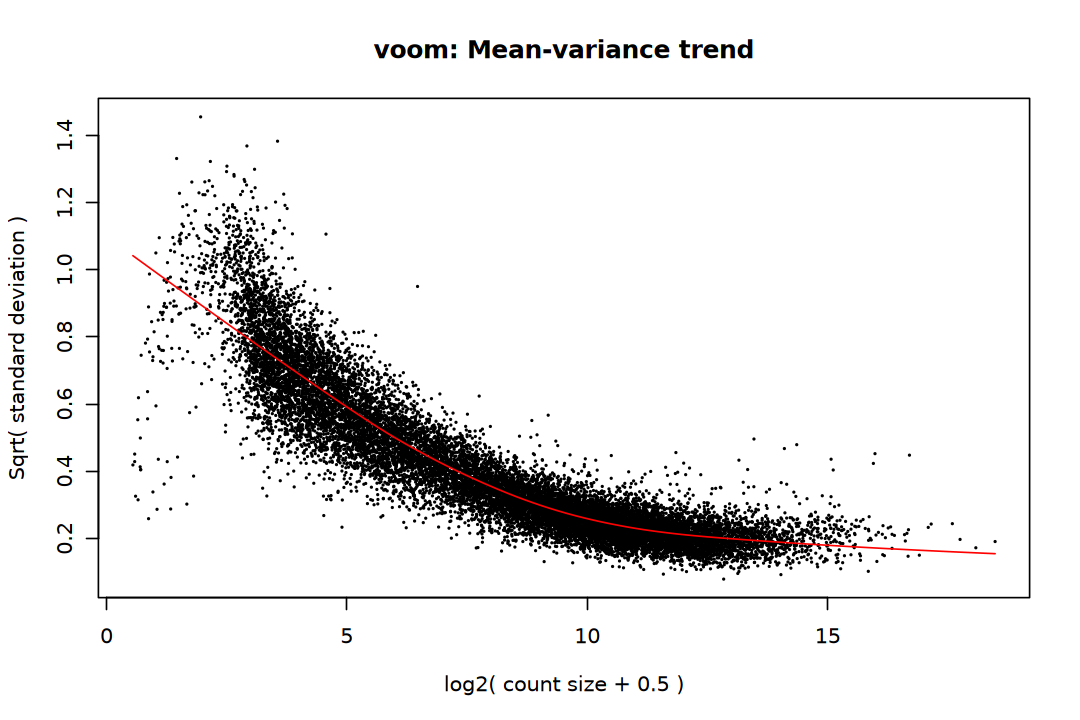

In [58]:
options(repr.plot.width = 9, repr.plot.height = 6)
v <- voom(dge, design, plot = TRUE)

In [59]:
# Linear Model for Series of Arrays
fit <- lmFit(v, design)
# Compute contrasts from linear model fit
fit <- contrasts.fit(fit, contrast_mat)
# Empirical Bayes Statistics for Differential Expression
fit <- eBayes(fit)

In [60]:
deg_limma_list <- lapply(colnames(contrast_mat), function(index) {
     topTable(fit, coef = index, number = Inf) |> 
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
        mutate(
            deg = case_when(
                padj < q_thred & logFC >  logFC_thred ~ "Up",
                padj < q_thred & logFC < -logFC_thred ~ "Down",
                TRUE ~ "NotSig"
            ) |> factor(levels = c("Up", "Down", "NotSig")), 
            compar = gsub(index, pattern = "-", replacement = "_vs_"))
}) |> set_names(compar_levels)

In [61]:
deg_df <- bind_rows(deg_limma_list) |>
    group_by(compar, deg) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                deg %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(compar = factor(compar, levels = compar_levels))

table(deg_df$deg, deg_df$compar)

        
         INV_vs_CTL RES_vs_CTL RES_vs_INV
  Up           2077        139       1230
  Down         1210        262       2086
  NotSig      14451      17337      14422

## Visualization

In [62]:
deg_df <- bind_rows(deg_deseq2_list) |>
    group_by(compar, deg) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                deg %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(compar = factor(compar, levels = compar_levels))

table(deg_df$deg, deg_df$compar)

        
         INV_vs_CTL RES_vs_CTL RES_vs_INV
  Up           1970         99       1214
  Down         1197        209       2006
  NotSig      14720      17579      14667

### Volcano

In [63]:
max_logfc <- deg_df$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

In [64]:
p1 <- ggplot(deg_df, aes(x = compar, y = logFC)) + 
    geom_point(aes(color = deg, size = deg), 
               position = position_jitter(width = 0.4, height = 0), 
               na.rm = TRUE, alpha = 0.6) +
    geom_tile(aes(x = compar, y = 0, fill = compar), 
              width = 0.9, height = 1.5, show.legend = FALSE) +
    geom_text(aes(x = compar, y = 0, label = compar), 
              color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NotSig" = 1),
        guide = "none") + 
    scale_color_manual(
        name = "DEG",
        values = c(Up = "LightCoral", Down = "SkyBlue", NotSig = "gray")) +
    guides(color = guide_legend(override.aes = list(size = 5))) +
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(axis.title = element_text(size = 20),
          axis.text.x = element_blank(),
          axis.text.y = element_text(size = 16),
          axis.ticks.x = element_blank(),
          axis.line.x = element_blank(),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

In [65]:
p2 <- ggplot(deg_df, aes(x = compar, y = logFC)) + 
    geom_point(aes(color = logFC, size = deg), 
               position = position_jitter(width = 0.4, height = 0), 
               na.rm = TRUE, alpha = 0.6) +
    geom_tile(aes(x = compar, y = 0, fill = compar), width = 0.9,
              height = 1.5, show.legend = FALSE) +
    geom_text(aes(x = compar, y = 0, label = compar),
              color = "black", size = 6) +
    geom_text_repel(
        aes(label = label), na.rm = TRUE, size = 5, 
        min.segment.length = 0, segment.size = 0.5,
        color = "black", max.overlaps = Inf) +
    scale_fill_brewer(palette = "Set2") + 
    scale_size_manual(
        values = c("Up" = 2, "Down" = 2, "NotSig" = 1),
        guide = "none") + 
    scale_color_gradientn(
        name = "logFC",
        colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25"), 
        limits = c(-max_logfc, max_logfc)) +
    # scale_color_viridis_c(
    #     name = "logFC", option = "turbo", begin = 0.1, end = 0.9, 
    #     limits = c(-max_logfc, max_logfc)) + 
    labs(x = "Comparisons", y = "LogFC") +
    theme_classic() +
    theme(axis.title = element_text(size = 20),
          axis.text.x = element_blank(),
          axis.text.y = element_text(size = 16),
          axis.ticks.x = element_blank(),
          axis.line.x = element_blank(),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

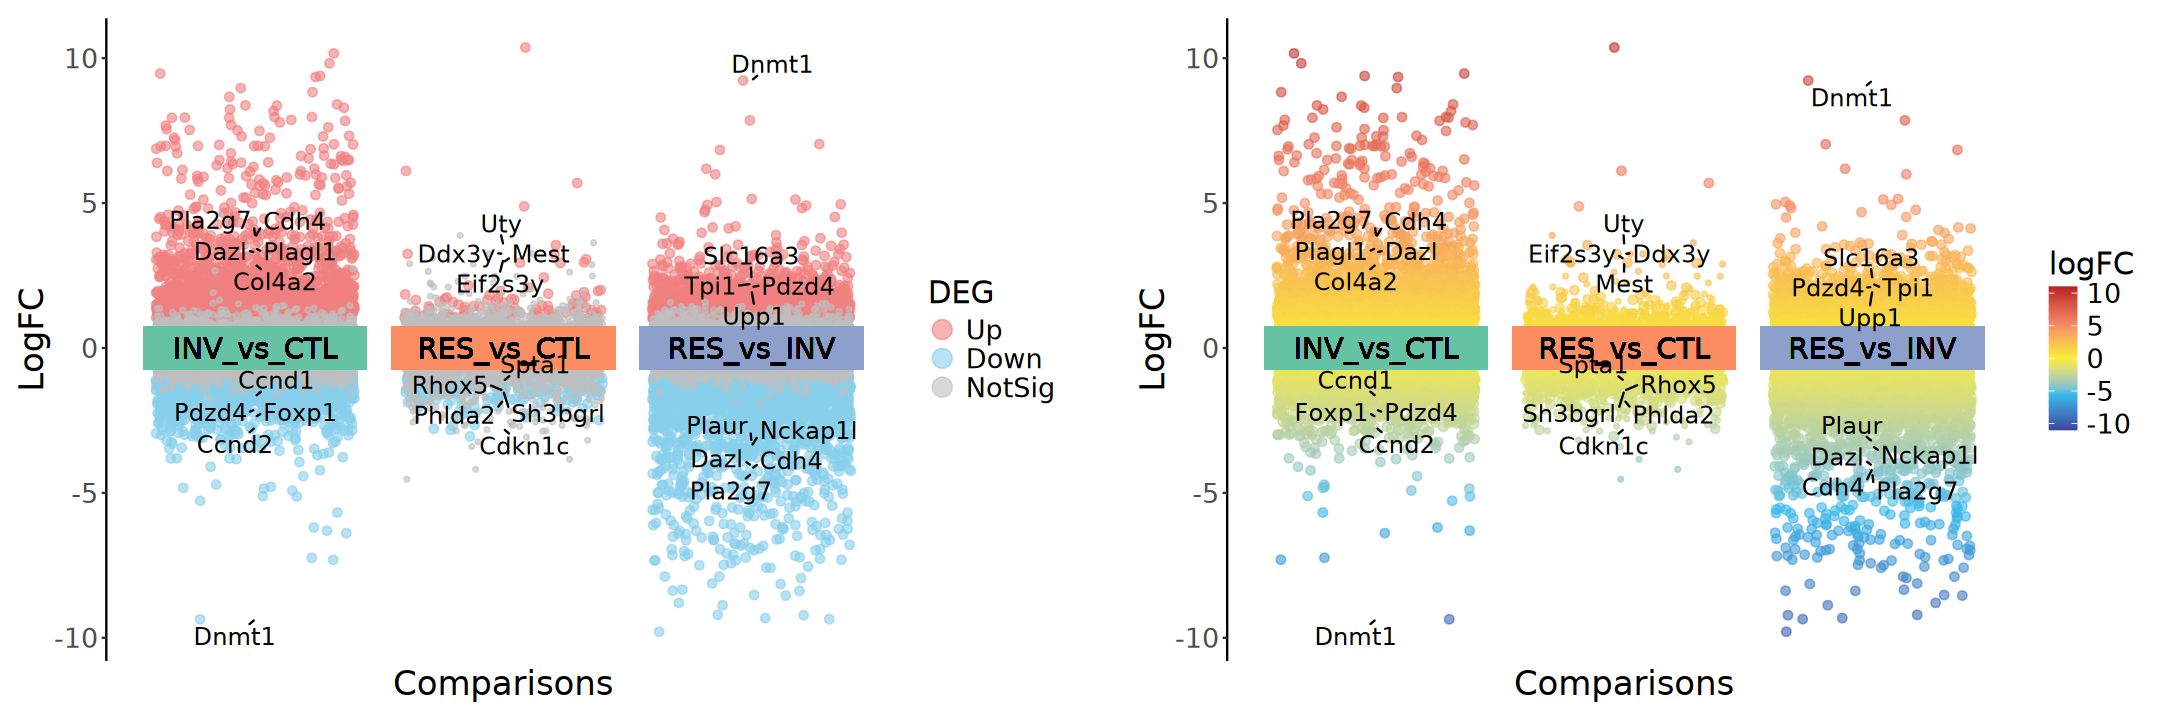

In [66]:
options(repr.plot.width = 18, repr.plot.height = 6)
p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### pheatmap

In [67]:
heatmap_dat <- deg_df |>
    filter(deg %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(genes) normExpr[genes, ])()

In [68]:
ar <- deg_df |> 
    dplyr::select(gene_id, compar, DEG = deg) |>
    pivot_wider(names_from = compar, values_from = DEG) |> 
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(compar_levels))

ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Replicate, Group)

In [69]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NotSig = "grey")

anno_colors <- setNames(
    replicate(3, deg_colors, simplify = FALSE),
    compar_levels)

anno_colors <- anno_colors |> 
    append(list(Group = group_colors,
                Replicate = replicate_colors))

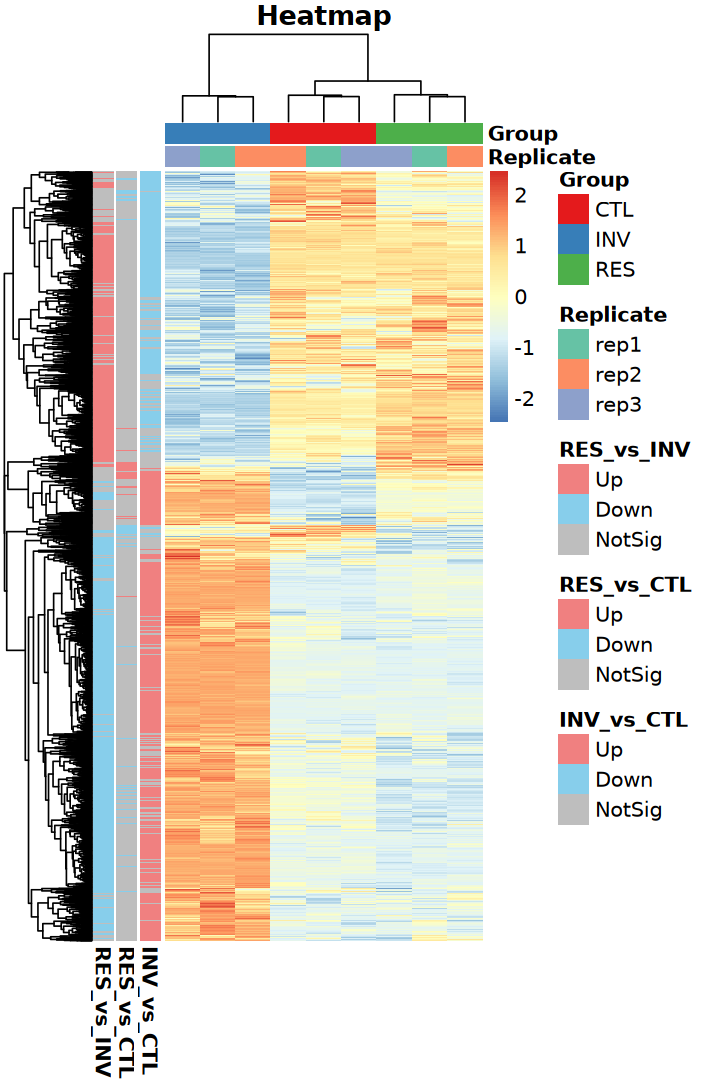

In [70]:
options(repr.plot.width = 6, repr.plot.height = 9)
pheatmap(heatmap_dat, scale = "row",
         annotation_row = ar, annotation_col = ac, 
         annotation_colors = anno_colors, 
         main = "Heatmap", fontsize = 12, 
         show_colnames = FALSE, show_rownames = FALSE)

### ComplexHeatmap

In [71]:
suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [72]:
heatmap_dat <- deg_df |>
    filter(deg %in% c("Up", "Down")) |>
    pull(gene_id) |>
    unique() |>
    (\(genes) normExpr[genes, ])()

In [73]:
heatmap_col <- colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = rev(brewer.pal(n = 3, name = "RdYlBu")))

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NotSig = "grey")

In [74]:
ac <- colData(dds) |> 
    as.data.frame() |>
    dplyr::select(Group, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Replicate = replicate_colors))

In [75]:
ar <- deg_df |> 
    dplyr::select(gene_id, compar, DEG = deg) |>
    pivot_wider(names_from = compar, values_from = DEG) |> 
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id") |> 
    dplyr::select(all_of(compar_levels))

anno_colors <- setNames(
    replicate(3, deg_colors, simplify = FALSE),
    compar_levels)

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [76]:
gene_labels <- deg_df |>
    dplyr::filter(!is.na(label)) |>
    dplyr::select(gene_id, label)

mark_rows <- which(rownames(heatmap_dat) %in% gene_labels$gene_id)
mark_labels <- gene_labels$label[match(rownames(heatmap_dat)[mark_rows], 
                                       gene_labels$gene_id)]

right_anno <- rowAnnotation(
    foo = anno_mark(
        at = mark_rows,
        labels = mark_labels,
        labels_gp = gpar(fontsize = 12)))

In [77]:
lg_heatmap <- Legend(title = "Expression (z-score)",
                     col_fun = heatmap_col)

lg_group <- Legend(title = "Group", 
                   labels = levels(dds$Group))

lg_replicate <- Legend(title = "Replicate", 
                       labels = levels(dds$Replicate))

lg_deg <- Legend(labels = levels(deg_df$deg), title = "DEG", 
                 legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [78]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(name = "Expression", col = heatmap_col,
            top_annotation = top_anno,
            left_annotation = left_anno, 
            right_annotation = right_anno,
            show_row_names = FALSE, show_column_names = FALSE)

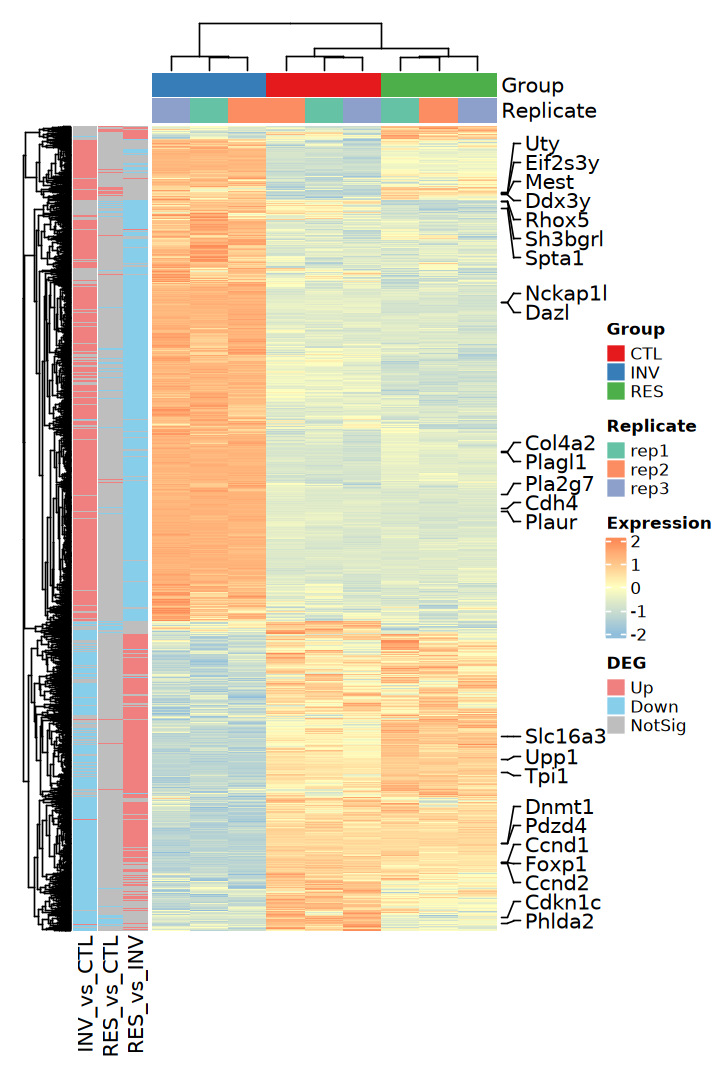

In [79]:
options(repr.plot.width = 6, repr.plot.height = 9)
draw(ht + combined_leg, merge_legend = TRUE,
     annotation_legend_list = list(lg_deg), 
     legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
     legend_labels_gp = gpar(fontsize = 10), 
     padding = unit(c(5, 5, 5, 5), "mm"))

### Sankey Plot

In [80]:
suppressPackageStartupMessages(library(ggalluvial))

In [81]:
sankey_long <- deg_df |> 
    dplyr::select(gene_id, compar, deg) |>
    mutate(deg = factor(deg, levels = c("Up", "NotSig", "Down"))) |>
    group_by(gene_id) |>
    filter(any(deg != "NotSig")) |>
    ungroup()

In [82]:
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NotSig = "grey")

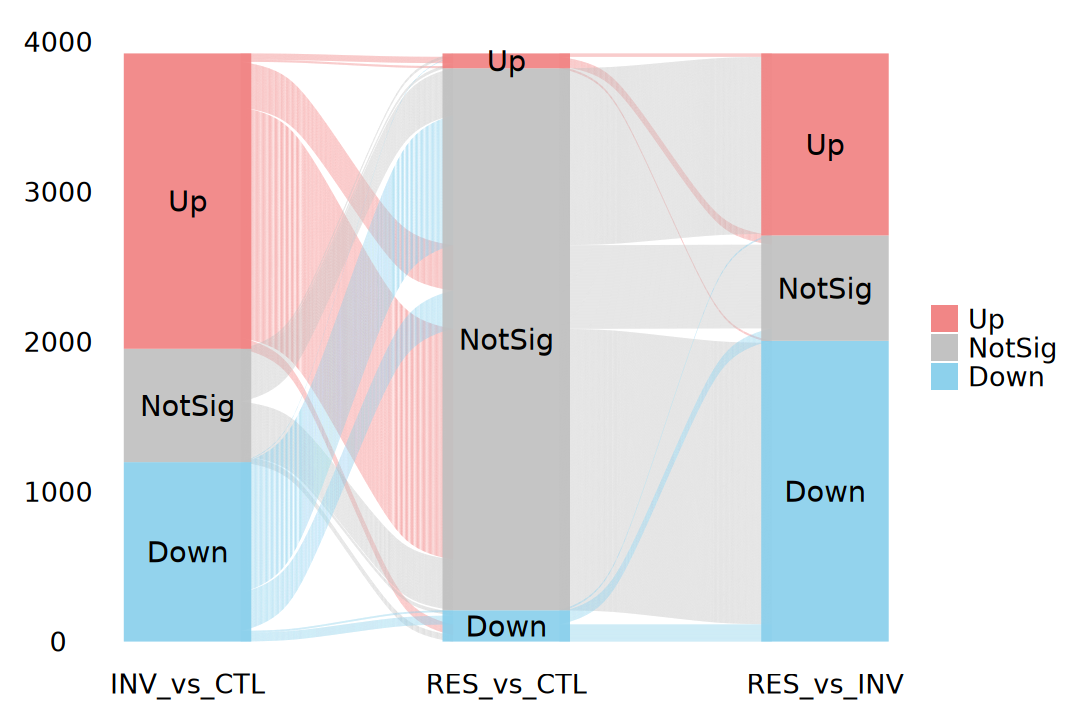

In [83]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(sankey_long, 
       aes(x = compar, stratum = deg, alluvium = gene_id,
           y = 1, fill = deg, label = deg)) +
    geom_flow(stat = "alluvium") +
    geom_stratum(width = 0.4, alpha = 0.9, color = NA) +
    geom_text(stat = "stratum", size = 6) +
    scale_x_discrete(limits = compar_levels, expand = c(.1, .1)) +
    scale_fill_manual(values = deg_colors) +
    labs(x = "Comparisons", y = "Gene count", fill = "DEG") +
    theme_void() +
    theme(axis.title = element_blank(),
          axis.text = element_text(size = 16),
          legend.title = element_blank(), 
          legend.text = element_text(size = 16), 
          plot.margin = unit(c(1, 1, 1, 1), "line"))

In [84]:
sankey_wide <- deg_df |> 
    dplyr::select(gene_id, compar, deg) |>
    mutate(deg = factor(deg, levels = c("Up", "NotSig", "Down"))) |>
    pivot_wider(names_from = compar, values_from = deg) |> 
    filter(if_any(all_of(compar_levels), ~ .x != "NotSig")) |>
    group_by(across(all_of(compar_levels))) |>
    summarise(Freq = n(), .groups = "drop")

Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
“Some strata appear at multiple axes.”


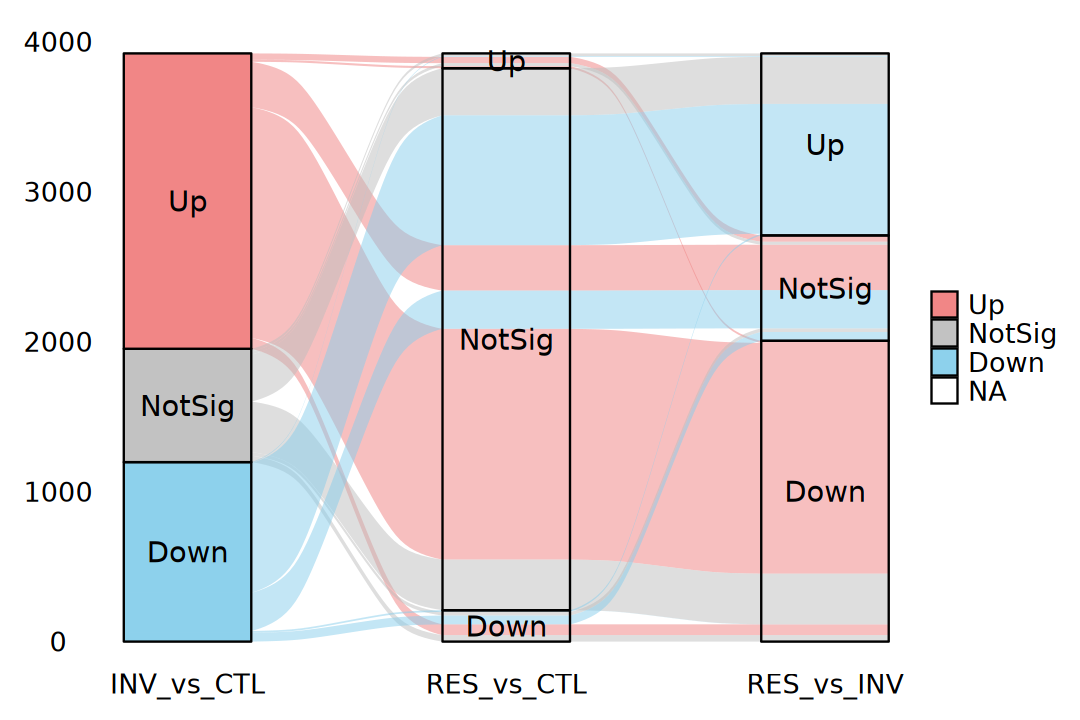

In [85]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(sankey_wide, 
       aes(axis1 = INV_vs_CTL, axis2 = RES_vs_CTL, 
           axis3 = RES_vs_INV, y = Freq, fill = INV_vs_CTL)) +
    geom_alluvium(width = 0.4, alpha = 0.5) +
    geom_stratum(width = 0.4, alpha = 0.9, color = "black") +
    geom_text(aes(label = after_stat(stratum)), 
              stat = "stratum", size = 6) +
    scale_x_discrete(limits = compar_levels, expand = c(.1, .1)) +
    scale_fill_manual(values = deg_colors, na.value = NA) +
    labs(x = "Comparisons", y = "Gene count", 
         fill = "Status in QKO_vs_WT") +
    theme_void() +
    theme(axis.title = element_blank(),
          axis.text = element_text(size = 16),
          legend.title = element_blank(), 
          legend.text = element_text(size = 16), 
          plot.margin = unit(c(1, 1, 1, 1), "line"))

### Venn

In [86]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [87]:
genes_up <- list(
    KO_vs_WT = deg_df$symbol[deg_df$deg == "Up" & deg_df$compar == "INV_vs_CTL"], 
    TKO_vs_WT = deg_df$symbol[deg_df$deg == "Up" & deg_df$compar == "RES_vs_CTL"], 
    QKO_vs_WT = deg_df$symbol[deg_df$deg == "Down" & deg_df$compar == "RES_vs_INV"])
genes_up <- lapply(genes_up, unique)

In [88]:
genes_down <- list(
    KO_vs_WT = deg_df$symbol[deg_df$deg == "Down" & deg_df$compar == "INV_vs_CTL"], 
    TKO_vs_WT = deg_df$symbol[deg_df$deg == "Down" & deg_df$compar == "RES_vs_CTL"], 
    QKO_vs_WT = deg_df$symbol[deg_df$deg == "Up" & deg_df$compar == "RES_vs_INV"])
genes_down <- lapply(genes_down, unique)

In [89]:
p1 <- ggVennDiagram(genes_up, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 6) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(genes_down, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 6) +
    scale_fill_distiller(palette = "Reds", direction = 1)

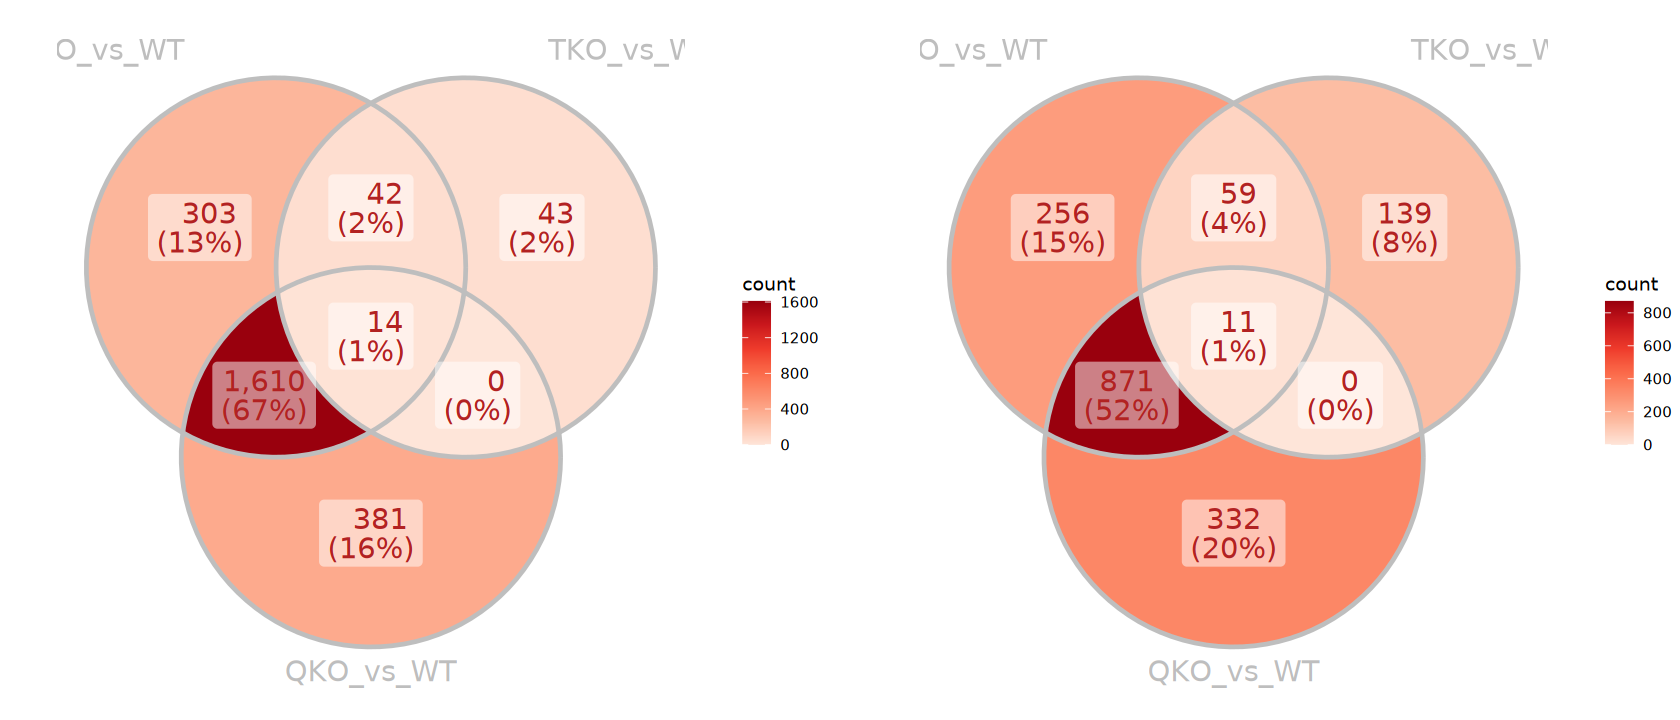

In [90]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## Evaluation results

### Volcano

In [91]:
add_label <- function(deg_list){
    deg_list |> 
        bind_rows() |>
        group_by(compar, deg) |>
        arrange(padj, logFC |> abs() |> desc()) |>
        mutate(
            label = ifelse(
                type == "protein_coding" & 
                    deg %in% c("Up", "Down") & 
                    row_number() <= 5, 
                symbol, NA_character_)) |>
        ungroup() |>
        mutate(compar = factor(compar, levels = compar_levels))
}

In [92]:
deg_deseq2 <- add_label(deg_deseq2_list)
deg_edgeR <- add_label(deg_edgeR_list)
deg_limma <- add_label(deg_limma_list)

In [93]:
ggplot_volcano <- function(plot_df){
    ggplot(plot_df, aes(x = compar, y = logFC)) + 
        geom_point(aes(color = deg, size = deg), 
                   position = position_jitter(width = 0.4, height = 0), 
                   na.rm = TRUE, alpha = 0.6) +
        geom_tile(aes(x = compar, y = 0, fill = compar), 
                  width = 0.9, height = 1.5, show.legend = FALSE) +
        geom_text(aes(x = compar, y = 0, label = compar), 
                  color = "black", size = 6) +
        geom_text_repel(
            aes(label = label), na.rm = TRUE, size = 5, 
            min.segment.length = 0, segment.size = 0.5,
            color = "black", max.overlaps = Inf) +
        scale_fill_brewer(palette = "Set2") + 
        scale_size_manual(
            values = c("Up" = 2, "Down" = 2, "NotSig" = 1),
            guide = "none") + 
        scale_color_manual(
            name = "DEG",
            values = c(Up = "LightCoral", Down = "SkyBlue", NotSig = "gray")) +
        guides(color = guide_legend(override.aes = list(size = 5))) +
        labs(x = "Comparisons", y = "LogFC") +
        theme_classic() +
        theme(axis.title = element_text(size = 20),
              axis.text.x = element_blank(),
              axis.text.y = element_text(size = 16),
              axis.ticks.x = element_blank(),
              axis.line.x = element_blank(),
              legend.title = element_text(size = 18),
              legend.text = element_text(size = 16))
}

In [94]:
p1 <- ggplot_volcano(deg_deseq2)
p2 <- ggplot_volcano(deg_edgeR)
p3 <- ggplot_volcano(deg_limma)

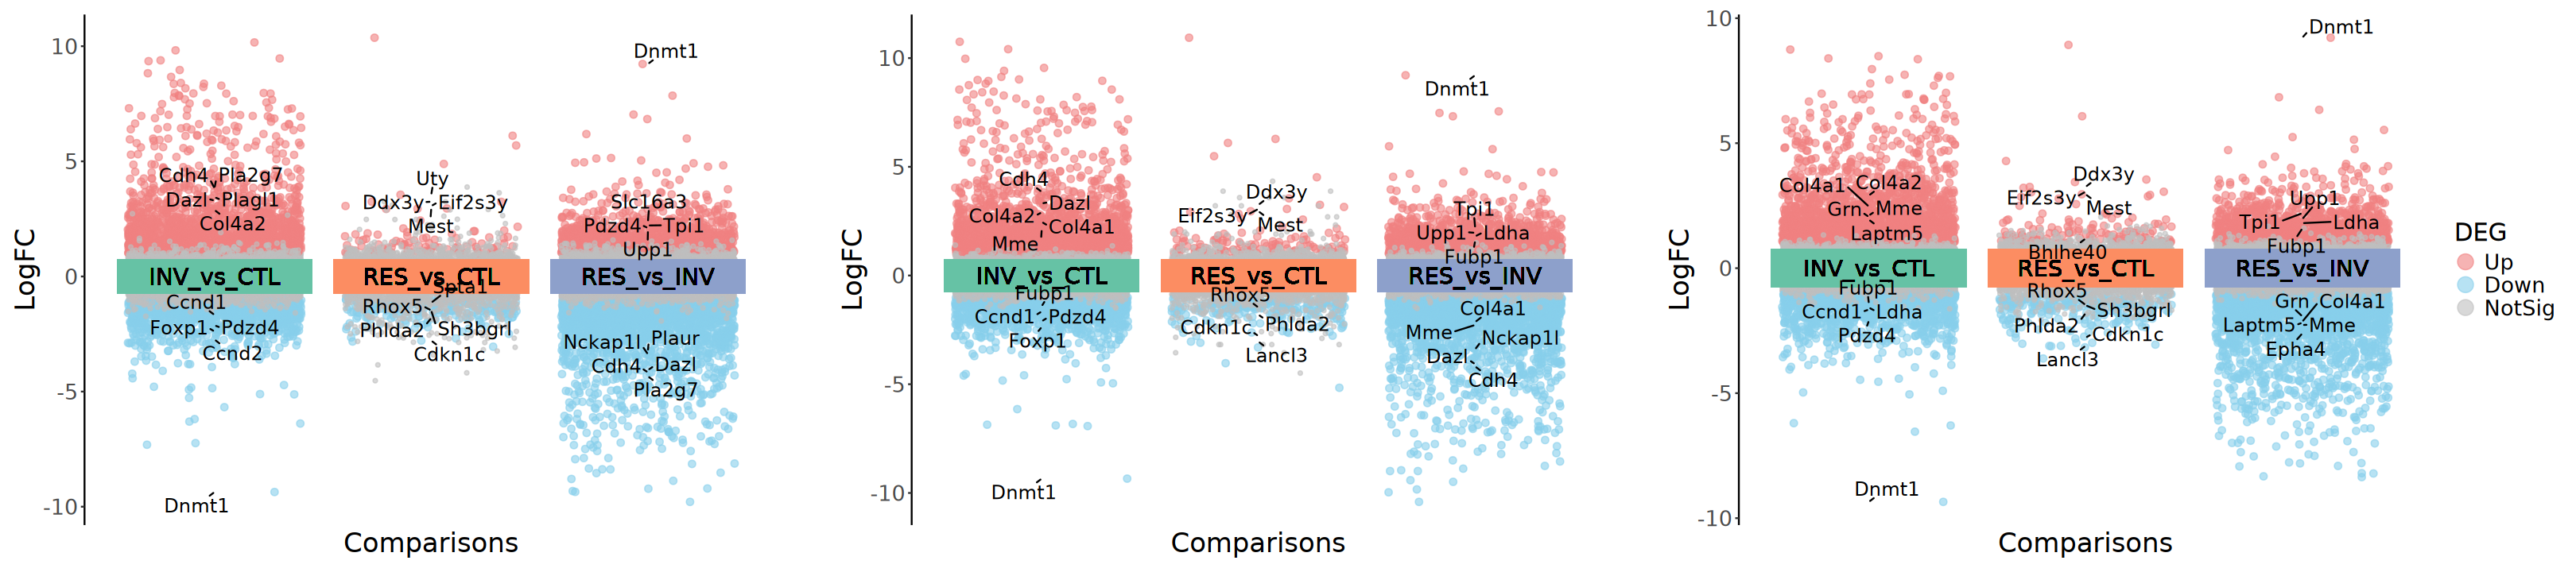

In [95]:
options(repr.plot.width = 27, repr.plot.height = 6)
p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [96]:
genes_up <- list(
    DESeq2 = deg_deseq2_list$INV_vs_CTL$symbol[deg_deseq2_list$INV_vs_CTL$deg == "Up"],
    edgeR = deg_edgeR_list$INV_vs_CTL$symbol[deg_edgeR_list$INV_vs_CTL$deg == "Up"], 
    limma = deg_limma_list$INV_vs_CTL$symbol[deg_limma_list$INV_vs_CTL$deg == "Up"])
genes_up <- lapply(genes_up, unique)

In [97]:
genes_down <- list(
    DESeq2 = deg_deseq2_list$INV_vs_CTL$symbol[deg_deseq2_list$INV_vs_CTL$deg == "Down"],
    edgeR = deg_edgeR_list$INV_vs_CTL$symbol[deg_edgeR_list$INV_vs_CTL$deg == "Down"],
    limma = deg_limma_list$INV_vs_CTL$symbol[deg_limma_list$INV_vs_CTL$deg == "Down"])
genes_down <- lapply(genes_down, unique)

In [98]:
p1 <- ggVennDiagram(genes_up, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(genes_down, set_color = "grey", set_size = 6, 
                    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

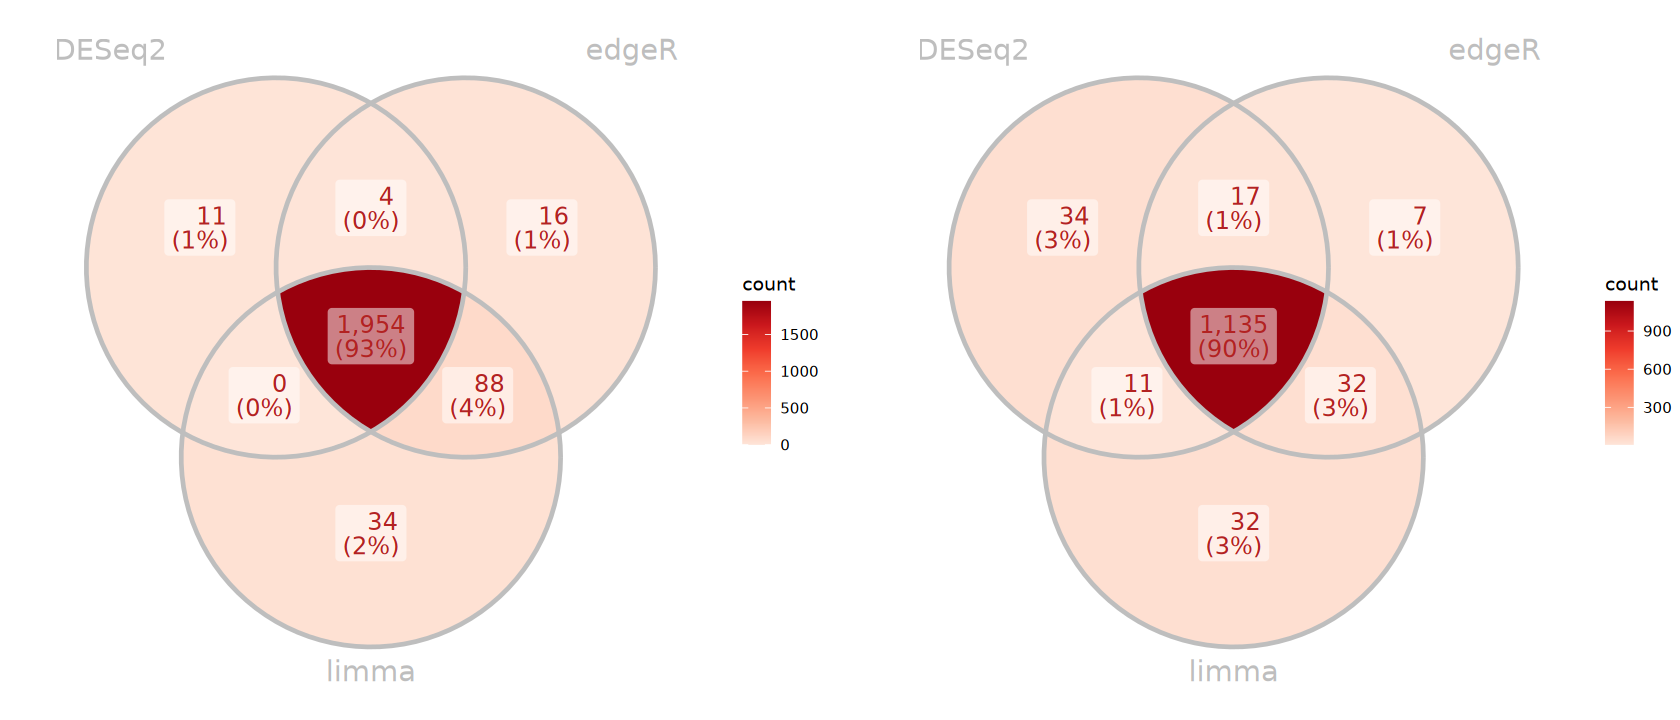

In [99]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Upset

In [100]:
suppressPackageStartupMessages(library(UpSetR))

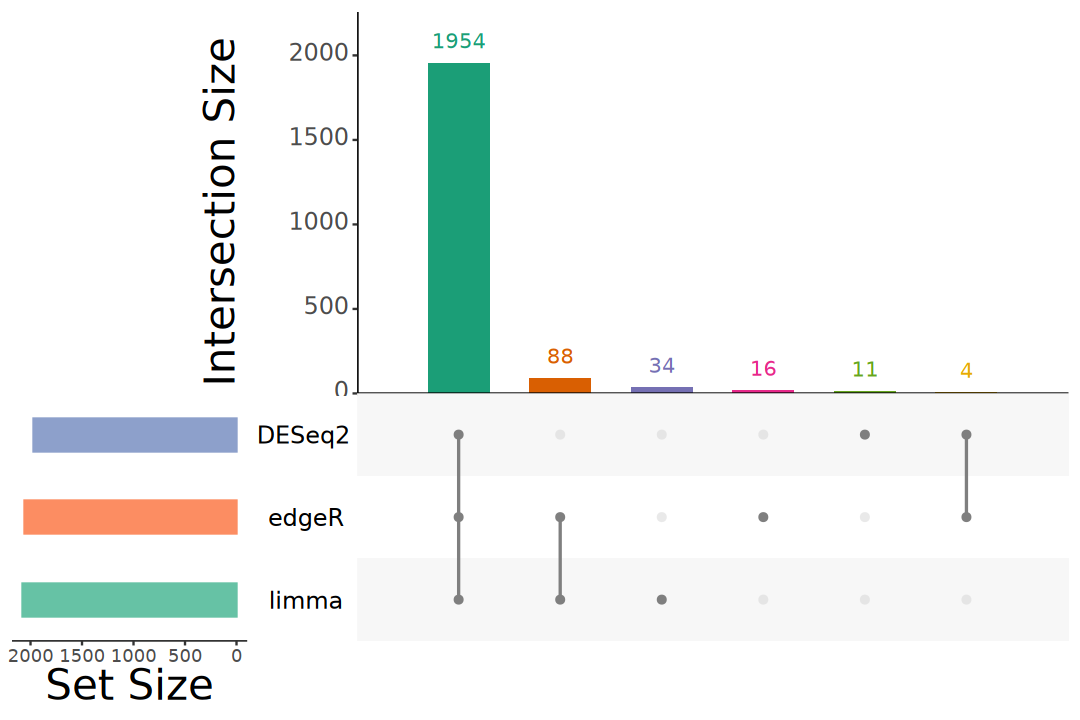

In [101]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 6, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

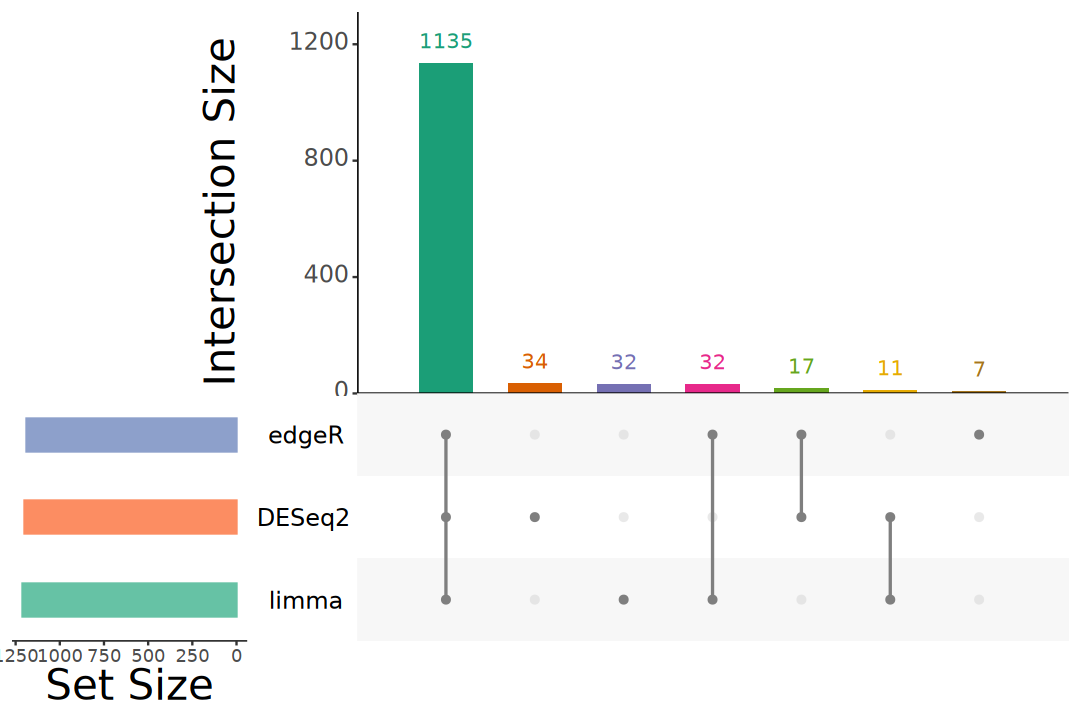

In [102]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

# 7. Gene Function Analysis

In [103]:
suppressPackageStartupMessages(library(clusterProfiler))
suppressPackageStartupMessages(library(org.Mm.eg.db))

In [104]:
deg_df <- bind_rows(deg_deseq2_list) |>
    group_by(compar, deg) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                deg %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(compar = factor(compar, levels = compar_levels))

table(deg_df$deg, deg_df$compar)

        
         INV_vs_CTL RES_vs_CTL RES_vs_INV
  Up           1970         99       1214
  Down         1197        209       2006
  NotSig      14720      17579      14667

In [105]:
add_ENTREZID <- function(deg_res, org_db, ignoreVersion = TRUE){
    if(ignoreVersion){
        deg_res$gene_id <- str_split(deg_res$gene_id, pattern = "\\.", simplify = TRUE)[, 1]
    }
    geneId <- bitr(deg_res$gene_id, OrgDb = org_db, drop = FALSE, 
                   fromType = "ENSEMBL", toType = c("ENTREZID", "SYMBOL"))
    deg_res$ENTREZID <- geneId$ENTREZID[match(deg_res$gene_id, geneId$ENSEMBL)]
    return(deg_res)
}

In [106]:
deg_df <- add_ENTREZID(deg_df, org.Mm.eg.db)
head(deg_df)

'select()' returned 1:many mapping between keys and columns

Warning message in bitr(deg_res$gene_id, OrgDb = org_db, drop = FALSE, fromType = "ENSEMBL", :
“12.42% of input gene IDs are fail to map...”


gene_id,baseMean,logFC,lfcSE,stat,pvalue,padj,deg,compar,symbol,type,basepairs,label,ENTREZID
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<chr>,<chr>,<int>,<chr>,<chr>
ENSMUSG00000004099,64390.2674,-9.361371,0.07215954,-129.73159,0,0,Down,INV_vs_CTL,Dnmt1,protein_coding,7377,Dnmt1,13433
ENSMUSG00000004099,64390.2674,9.228435,0.07216532,127.87909,0,0,Up,RES_vs_INV,Dnmt1,protein_coding,7377,Dnmt1,13433
ENSMUSG00000023913,755.6180,-4.336508,0.10333295,-41.96636,0,0,Down,RES_vs_INV,Pla2g7,protein_coding,2905,Pla2g7,27226
ENSMUSG00000000305,837.0958,-4.165902,0.09437960,-44.13985,0,0,Down,RES_vs_INV,Cdh4,protein_coding,7257,Cdh4,12561
ENSMUSG00000010592,952.2127,-4.062729,0.08686507,-46.77057,0,0,Down,RES_vs_INV,Dazl,protein_coding,3820,Dazl,13164
ENSMUSG00000023913,755.6180,3.847821,0.09235469,41.66351,0,0,Up,INV_vs_CTL,Pla2g7,protein_coding,2905,Pla2g7,27226


In [107]:
# Comparing multiple gene lists
geneList <- list(
    INV_vs_CTL_up = deg_df$symbol[deg_df$deg == "Up" & deg_df$compar == "INV_vs_CTL"], 
    RES_vs_CTL_up = deg_df$symbol[deg_df$deg == "Up" & deg_df$compar == "RES_vs_CTL"], 
    RES_vs_INV_down = deg_df$symbol[deg_df$deg == "Down" & deg_df$compar == "RES_vs_INV"],
    INV_vs_CTL_down = deg_df$symbol[deg_df$deg == "Down" & deg_df$compar == "INV_vs_CTL"], 
    RES_vs_CTL_down = deg_df$symbol[deg_df$deg == "Down" & deg_df$compar == "RES_vs_CTL"], 
    RES_vs_INV_up = deg_df$symbol[deg_df$deg == "Up" & deg_df$compar == "RES_vs_INV"])
geneList <- lapply(geneList, unique)

In [108]:
mego_res <- compareCluster(
    geneCluster = geneList, fun = enrichGO, 
    universe = unique(deg_df$symbol), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [109]:
mego_res |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,INV_vs_CTL_up,BP,GO:0008015,blood circulation,97/1583,395/14643,0.2455696,2.271558,8.919218,3.144827e-15,1.100296e-11,8.866676e-12,97
2,INV_vs_CTL_up,BP,GO:0003013,circulatory system process,101/1583,421/14643,0.2399050,2.219159,8.836701,4.277980e-15,1.100296e-11,8.866676e-12,101
3,INV_vs_CTL_up,BP,GO:1903522,regulation of blood circulation,55/1583,197/14643,0.2791878,2.582531,7.785396,1.795249e-11,3.078253e-08,2.480593e-08,55
4,INV_vs_CTL_up,BP,GO:0007389,pattern specification process,86/1583,390/14643,0.2205128,2.039778,7.245845,6.021390e-11,7.743508e-08,6.240062e-08,86
5,INV_vs_CTL_up,BP,GO:0030198,extracellular matrix organization,62/1583,251/14643,0.2470120,2.284900,7.148494,2.607242e-10,2.235276e-07,1.801284e-07,62
6,INV_vs_CTL_up,BP,GO:0045229,external encapsulating structure organization,62/1583,251/14643,0.2470120,2.284900,7.148494,2.607242e-10,2.235276e-07,1.801284e-07,62


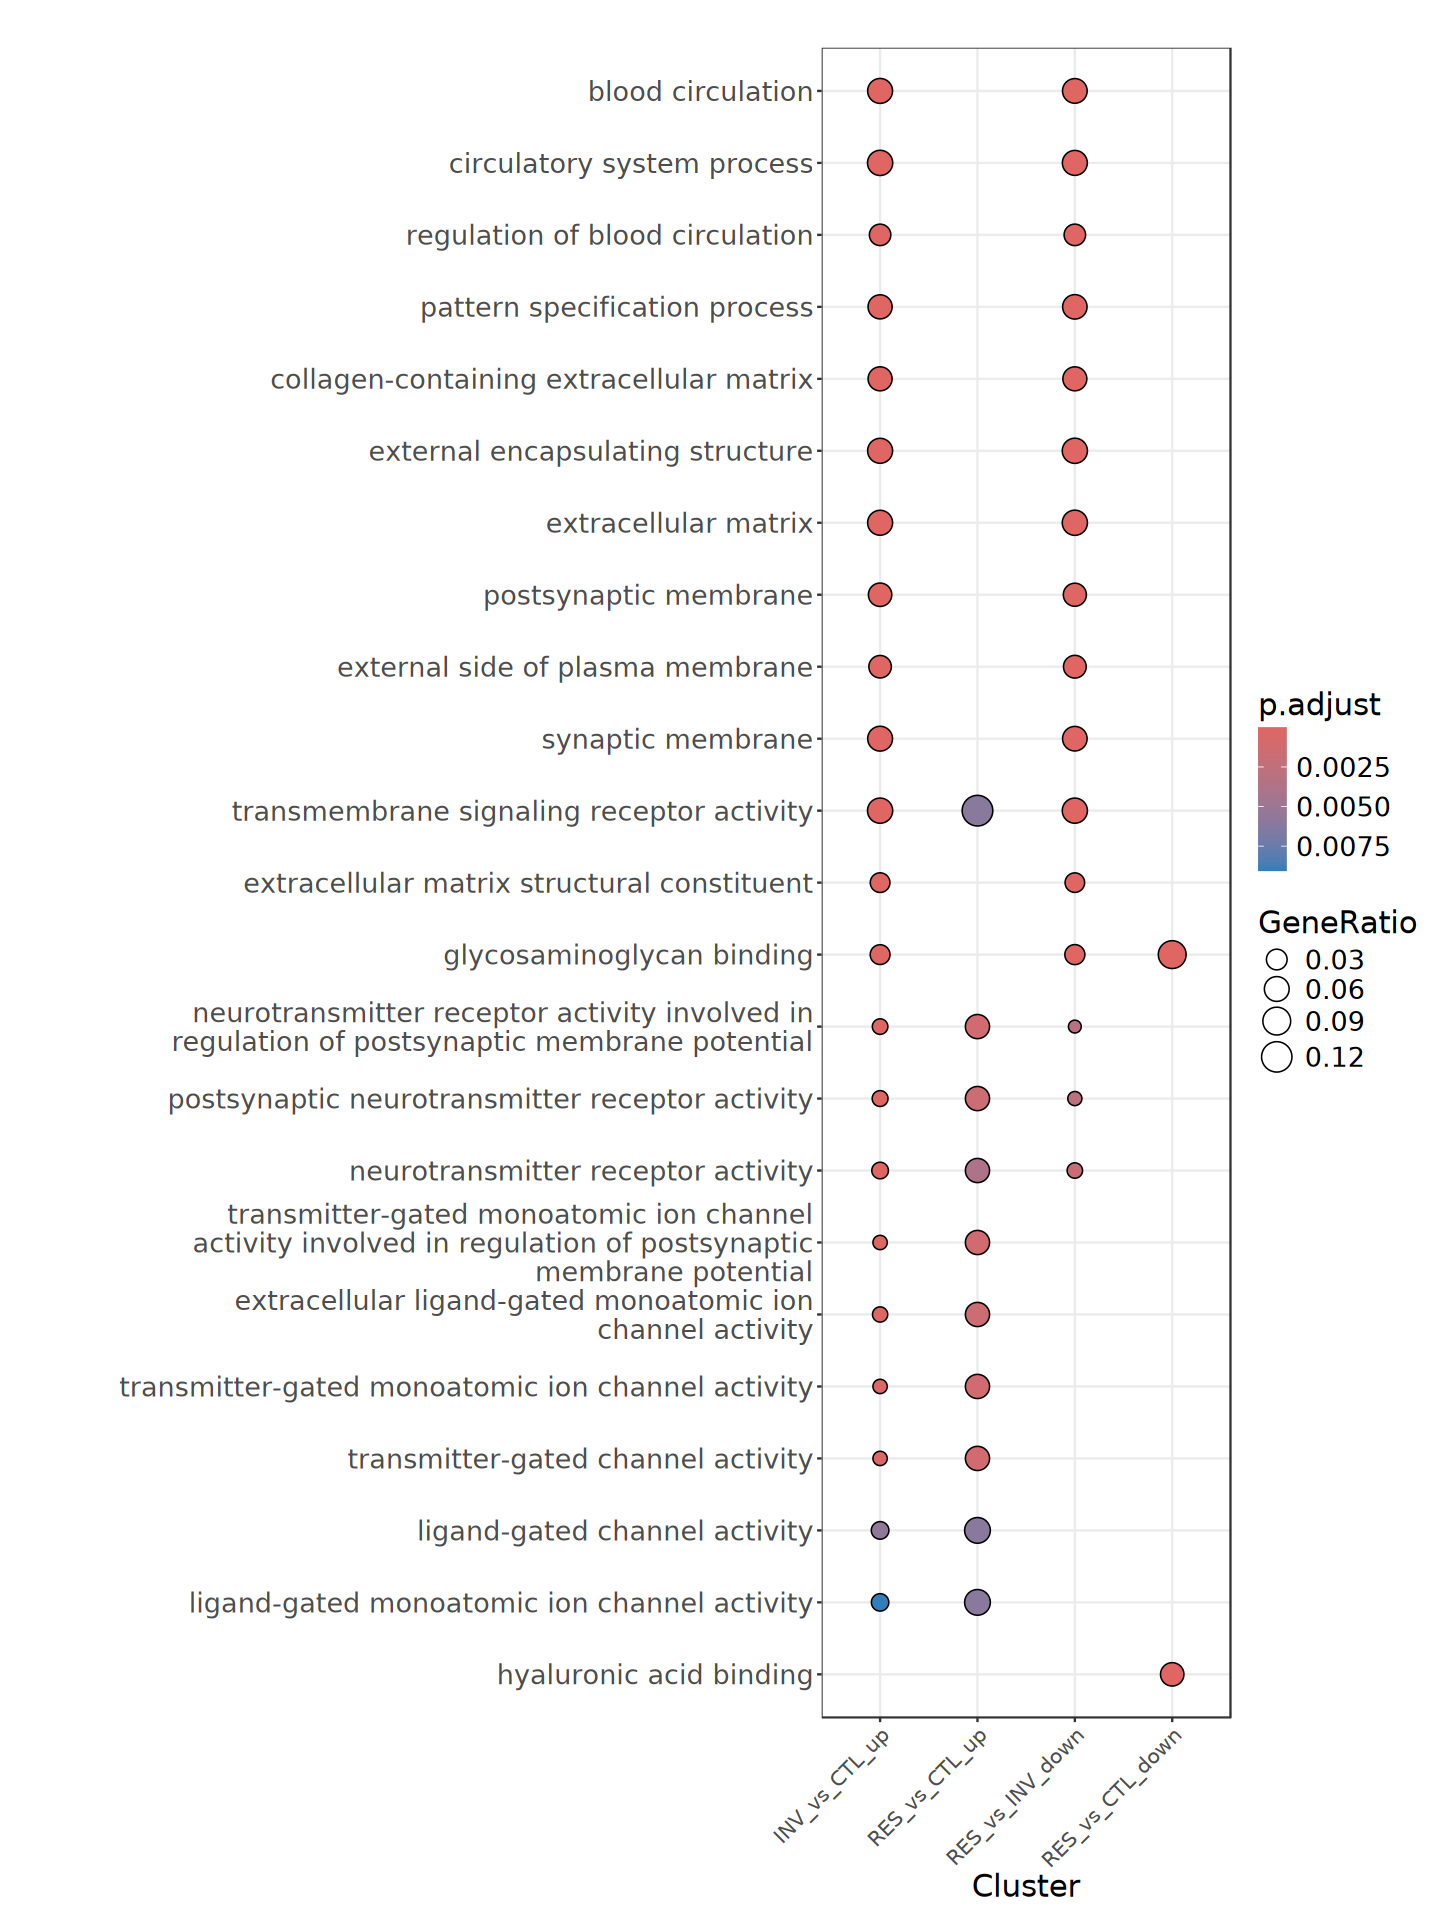

In [110]:
options(repr.plot.width = 12, repr.plot.height = 16)
dotplot(mego_res, showCategory = 10, label_format = 50) + 
    theme_bw() +
    theme(axis.title = element_text(size = 18), 
          axis.text.x = element_text(size = 12, angle = 45, hjust = 1), 
          axis.text.y = element_text(size = 16), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16), 
          plot.margin = margin(t = 10, r = 10, b = 10, l = 80))

In [111]:
# Comparing multiple gene lists
geneList <- list(
    INV_vs_CTL_up = deg_df$ENTREZID[deg_df$deg == "Up" & deg_df$compar == "INV_vs_CTL"], 
    RES_vs_CTL_up = deg_df$ENTREZID[deg_df$deg == "Up" & deg_df$compar == "RES_vs_CTL"], 
    RES_vs_INV_down = deg_df$ENTREZID[deg_df$deg == "Down" & deg_df$compar == "RES_vs_INV"],
    INV_vs_CTL_down = deg_df$ENTREZID[deg_df$deg == "Down" & deg_df$compar == "INV_vs_CTL"], 
    RES_vs_CTL_down = deg_df$ENTREZID[deg_df$deg == "Down" & deg_df$compar == "RES_vs_CTL"], 
    RES_vs_INV_up = deg_df$ENTREZID[deg_df$deg == "Up" & deg_df$compar == "RES_vs_INV"])
geneList <- lapply(geneList, unique)

In [112]:
mekegg_res <- compareCluster(
    geneCluster = geneList, fun = enrichKEGG, 
    universe = unique(deg_df$ENTREZID), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05,
    minGSSize = 10, maxGSSize = 500)

In [113]:
mekegg_res |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,INV_vs_CTL_up,Environmental Information Processing,Signal transduction,mmu04024,cAMP signaling pathway,47/685,165/6199,0.2848485,2.577775,7.239724,3.490017e-10,1.130766e-07,9.147519e-08,47
2,INV_vs_CTL_up,Environmental Information Processing,Signal transduction,mmu04022,cGMP-PKG signaling pathway,38/685,136/6199,0.2794118,2.528574,6.352577,3.192875e-08,5.172457e-06,4.184346e-06,38
3,INV_vs_CTL_up,Environmental Information Processing,Signaling molecules and interaction,mmu04080,Neuroactive ligand-receptor interaction,41/685,159/6199,0.2578616,2.333554,6.003829,1.083867e-07,1.170577e-05,9.469577e-06,41
4,INV_vs_CTL_up,Cellular Processes,Cell motility,mmu04820,Cytoskeleton in muscle cells,46/685,191/6199,0.2408377,2.179493,5.835591,1.659749e-07,1.344397e-05,1.087572e-05,46
5,INV_vs_CTL_up,Metabolism,Metabolism of cofactors and vitamins,mmu00830,Retinol metabolism,13/685,26/6199,0.5000000,4.524818,6.347648,8.669067e-07,5.617555e-05,4.544416e-05,13
6,INV_vs_CTL_up,NA,NA,mmu04082,Neuroactive ligand signaling,32/685,120/6199,0.2666667,2.413236,5.509687,1.243744e-06,6.716216e-05,5.433196e-05,32


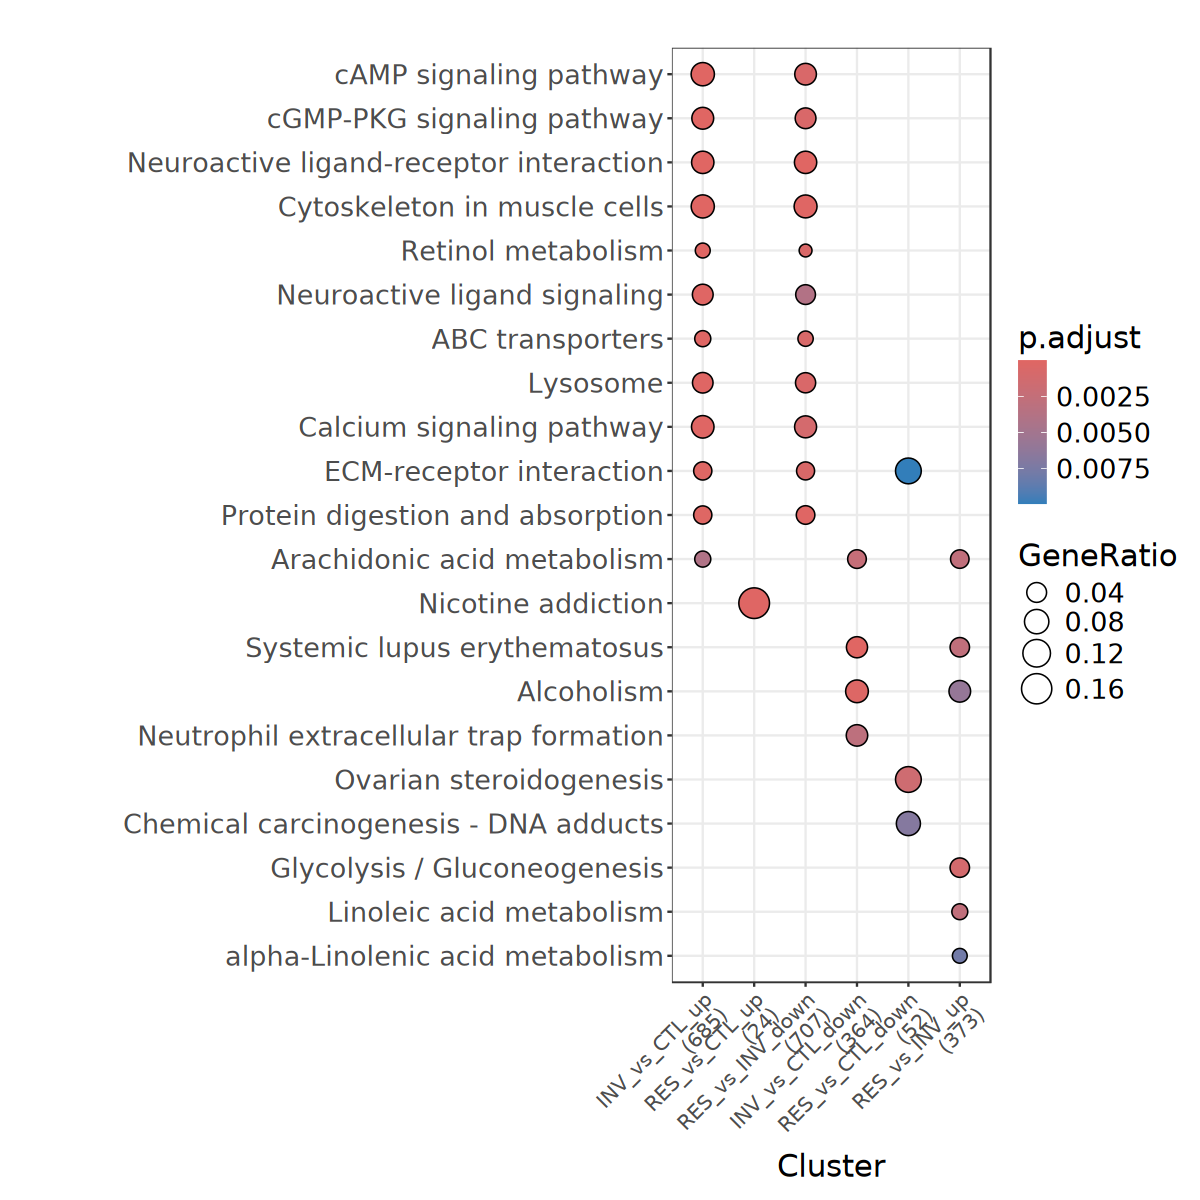

In [114]:
options(repr.plot.width = 10, repr.plot.height = 10)
dotplot(mekegg_res, showCategory = 10, label_format = 50) + 
    theme_bw() +
    theme(axis.title = element_text(size = 18), 
          axis.text.x = element_text(size = 12, angle = 45, hjust = 1), 
          axis.text.y = element_text(size = 16), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16), 
          plot.margin = margin(t = 10, r = 10, b = 10, l = 80))